In [1]:
%load_ext autoreload
%autoreload 2
%reload_ext autoreload

In [2]:
import pandas as pd
from tqdm.notebook import tqdm
import ast
tqdm.pandas()
from socialvec.socialvec import SocialVec
import random

from utils import parse_friends_ids

2026-01-19 07:49:56.035609: I tensorflow/core/util/port.cc:111] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-01-19 07:49:57.539655: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-01-19 07:49:58.827876: E tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:9342] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-01-19 07:49:58.827922: E tensorflow/compiler/xla/stream_executor/cuda/cuda_fft.cc:609] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-01-19 07:49:58.834372: E tensorflow/compiler/xla/stream_executor/cuda/cuda_blas.cc:1518] Unable to register cuBLAS factory: Attempting to regi

In [87]:
all_topics = pd.read_excel("../data/popular_accounts_manually_validated.xlsx", sheet_name=None)
#df_users = pd.read_excel("../data/new_mean_average_percision.xlsx", sheet_name="SelectedUsers")
df_users = pd.read_pickle("../data/users_selected_for_the_experiment2.pkl")


In [88]:
#df_users = pd.read_csv("../data/users_selected_for_the_experiment.csv")

In [89]:
df_users['friends_count'] = df_users['friends_count'].astype(int)

In [90]:
# if you used the excel for the df_users, you need to parse the users:
#convert data from string to list
#df_users["friends_ids"] = df_users.apply(parse_friends_ids, axis=1)

In [91]:
df_users[df_users['friends_count']!=0]['friends_count'].describe().apply(lambda x: format(x, ',.02f'))

count    13,798.00
mean      1,754.86
std       1,428.83
min           1.00
25%         603.00
50%       1,289.00
75%       2,559.00
max       5,000.00
Name: friends_count, dtype: object

In [92]:
df_users = df_users[~df_users['account_selected_for'].isna()]

In [93]:
df_accounts = pd.DataFrame()

for i in all_topics:
    all_topics[i] = all_topics[i][all_topics[i]['use']==1].copy()
    df_accounts = pd.concat([df_accounts, all_topics[i]])

df_accounts = df_accounts[df_accounts['use']==1]
df_accounts['twitter_user_id'] = df_accounts['twitter_user_id'].astype(int)
df_accounts.drop(df_accounts.columns[df_accounts.columns.str.contains('unnamed',case = False)],axis = 1, inplace = True)

In [94]:
df_accounts['followers_count'].describe().apply(lambda x: format(x, ',.02f'))

count            276.00
mean       8,366,736.22
std       18,025,941.11
min           20,642.00
25%          510,939.00
50%        1,873,836.00
75%        6,500,807.50
max      115,819,215.00
Name: followers_count, dtype: object

In [97]:
account_list = df_accounts['twitter_user_id'].values
topic_list = [t for t in all_topics]

In [98]:
#keep only users with the relevant topics (since we removed some)
print(df_users.shape[0])
df_users = df_users[df_users['topic'].isin(topic_list)]
print(df_users.shape[0])

13800
13800


In [99]:
def get_relevant_subset_users(x):
    return list(set(x).intersection(set(account_list)))

In [100]:
df_users["number_of_accounts_full_sv"] = df_users["friends_ids"].apply(lambda x: len(x))
df_users["experiment_accounts"] = df_users["friends_ids"].apply(get_relevant_subset_users)
df_users["number_of_accounts_from_experiment"] = df_users["experiment_accounts"].apply(lambda x: len(x))

In [101]:
df_users["number_of_accounts_from_experiment"].describe().apply(lambda x: format(x, ',.02f'))

count    13,800.00
mean         33.74
std          25.69
min           1.00
25%          13.00
50%          27.00
75%          49.00
max         170.00
Name: number_of_accounts_from_experiment, dtype: object

In [102]:
minimal_number_of_accounts = 10

number_of_users_before_filtering = df_users.shape[0]
df_users = df_users[df_users["number_of_accounts_from_experiment"]>minimal_number_of_accounts]
print(f"removed {number_of_users_before_filtering - df_users.shape[0]} users in order to use only users who follow more than {minimal_number_of_accounts} users")
print(f"Using {df_users.shape[0]/number_of_users_before_filtering:.0%} of the users")

removed 2647 users in order to use only users who follow more than 10 users
Using 81% of the users


In [103]:
def find_number_of_categories_per_user(list_of_accounts):
    num_of_categories = 0
    for t in all_topics:
        all_topics[t]['twitter_user_id'] = all_topics[t]['twitter_user_id'].astype(int)
        if len (set(all_topics[t]['twitter_user_id'].values).intersection(set(list_of_accounts))) > 0:
            num_of_categories += 1
    return num_of_categories

In [104]:
df_users['number_of_categories_this_user_follows'] = df_users["experiment_accounts"].progress_apply(find_number_of_categories_per_user)

  0%|          | 0/11153 [00:00<?, ?it/s]

In [105]:
sv = SocialVec()

✅  Initializing Model
✅  Load Metadata


In [106]:
df_users["experiment_accounts_str"] = df_users["experiment_accounts"].progress_apply(lambda x: [str(i) for i in x])

  0%|          | 0/11153 [00:00<?, ?it/s]

### 16. Separation Logic
Define function to split friends into **Topic Accounts** (ground truth) and **Non-Topic Accounts** (context for embedding)

In [107]:
def seperate_topic_accounts(user_account_list, topic_account_list):
    user_accounts = set(user_account_list)
    topic_accounts = set(topic_account_list)
    return list(user_accounts - topic_accounts), list(user_accounts.intersection(topic_accounts))

In [108]:
from scipy.spatial.distance import cosine
import numpy as np
from typing import List, Tuple, Dict

def get_sv_rank(
    user_vec: np.ndarray,
    relevant_vecs: pd.DataFrame
) -> pd.DataFrame:
    """
    Build a DataFrame of cosine similarities between one user vector and
    all relevant account vectors.
    """
    records = []
    for i, row in relevant_vecs.iterrows():
        records.append({
            'account': row['twitter_screen_name'],
            'twitter_user_id':row['twitter_user_id'],
            'similarity': cosine(row['account_sv'], user_vec)
        })
    sv_ranked_list = pd.DataFrame(records).sort_values(by='similarity', ascending=True).reset_index(drop=True).reset_index()
    sv_ranked_list.rename(columns={'index':'rank'}, inplace=True)
    sv_ranked_list['rank'] = sv_ranked_list['rank'] + 1
    return sv_ranked_list

def get_popular_rank(
        relevant_vecs: pd.DataFrame
) -> pd.DataFrame:
    popularity_rank = relevant_vecs.sort_values(by=['followers_count'], ascending=False).reset_index(drop=True).reset_index()
    popularity_rank.rename(columns={'index':'rank',
                                    'twitter_screen_name':'account'}, inplace=True)
    popularity_rank['rank'] = popularity_rank['rank'] + 1
    return popularity_rank[['rank','account','twitter_user_id']]

### 17. Ranking Functions
Define `get_sv_rank` (Cosine Similarity) and `get_popular_rank` (Follower Count) to rank accounts.

### 18. Metric: Mean Average Precision (MAP)

### 19. Rank Normalization
Helper to filter a full ranked list down to specific topic accounts and reset rank indices (1, 2, 3...)

In [109]:
def reset_and_rank_topic_accounts(df, topic_accounts):
    df = df[df['twitter_user_id'].isin(topic_accounts)]
    df = df.reset_index(drop=True)
    df = df.reset_index()
    df['index'] = df['index'] + 1
    return df

### 20. Pre-calculate Embeddings
Compute SocialVec embeddings for all topic accounts once to optimize performance.

In [110]:
# Calculate Topics SV
for topic in topic_list:
    #all_topics[topic]['twitter_user_id'] = all_topics[topic]['twitter_user_id'].astype(int).astype(str)
    all_topics[topic]['account_sv'] = all_topics[topic]['twitter_user_id'].apply(lambda x: sv[x])

### 21. Topic Data Preparation
Define function to separate friends lists into context/target sets for a specific topic experiment.

In [113]:
def prepare_df_for_topic(topic, df_users):
    df_for_topic = df_users[df_users['topic'] == topic].copy()
    df_for_topic[["non_topic_accounts","topic_accounts"]] = df_for_topic['experiment_accounts'].apply( lambda x: pd.Series(seperate_topic_accounts(x,all_topics[topic]['twitter_user_id'].values)))
    # Just for visibility and debug, save the account names also
    #df_for_topic['topic_accounts_str'] = df_for_topic['topic_accounts'].apply(lambda x:[sv.get_screen_name(str(i) )for i in x])
    #df_for_topic['non_topic_accounts_str'] = df_for_topic['non_topic_accounts'].apply(lambda x:[sv.get_screen_name(str(i) )for i in x])
    return df_for_topic

In [114]:
def list_str(my_list):
    return [str(i) for i in my_list]

### 23. Pre-process All Topics
Loop through all topics and prepare the dataframes using the function defined above.",

In [115]:
df_for_all_topic = {}
for topic in (pbar := tqdm(topic_list)):
    pbar.set_description(f"Preparing topic {topic}")
    df_for_all_topic[topic] = prepare_df_for_topic(topic, df_users)

  0%|          | 0/14 [00:00<?, ?it/s]

### 23.5 temp statistics

In [ ]:
df_stats = pd.DataFrame()

for topic in (pbar := tqdm(topic_list)):
    #pbar.set_description(f"Preparing topic {topic}")
    #df_for_topic = prepare_df_for_topic(topic, df_users)
    df_for_topic = df_for_all_topic[topic].copy()
    
    df_for_topic['number_of_non_topic_accounts'] = df_for_topic['non_topic_accounts'].apply(lambda x: len(x))
    df_for_topic['number_of_topic_accounts'] = df_for_topic['topic_accounts'].apply(lambda x: len(x))
    df_for_topic['topic'] = topic
    
    df_stats = pd.concat([df_stats,df_for_topic])

In [ ]:
pd.options.display.float_format = "{:,.2f}".format

In [ ]:
df_stats[['topic','friends_ids_len',
              'number_of_accounts_from_experiment',
              'number_of_categories_this_user_follows',
              'number_of_non_topic_accounts',
              'number_of_topic_accounts' ]].describe().T


In [ ]:
del df_stats

## 24. Mean Average Precision (MAP) Calculations for the experiment 'small' world
Iterate through all topics and users. Calculate MAP scores for:

1. **Full SocialVec**: Using all non-topic friends.
2. **Sampled SocialVec**: Using random subsets (10-50 friends).
3. **Popularity**: Using follower counts.

In [ ]:
map_all_topics = pd.DataFrame()

for topic in (pbar := tqdm(topic_list)):
    pbar.set_description(f"Preparing topic {topic}")
    #df_for_topic = prepare_df_for_topic(topic, df_users)
    df_for_topic = df_for_all_topic[topic]
    map_result = pd.DataFrame()

    for i, user in tqdm(df_for_topic.iterrows()):    

        pbar.set_description(f"Processing topic: {topic} user: {user['screen_name']}")
        user_all_accounts = list_str(user['friends_ids'])
        user_all_accounts_except_selected_accounts = list( set(user_all_accounts) - set(user['topic_accounts_str']) )
        user_experiment_account_except_selected_accounts = user['non_topic_accounts_str']
        
        # Get SV rank when using all of the accounts that the user follows
        all_sv_rank = get_sv_rank(sv.get_average_embeddings(user_all_accounts_except_selected_accounts)[0],all_topics[topic])
        all_sv_rank = reset_and_rank_topic_accounts(all_sv_rank, user['topic_accounts'])
        
        # Try differet thresholds of 
        sample_result_data = {}
        for sample_size in [10, 20, 30, 40, 50]:
            if sample_size < len(user['non_topic_accounts']):
                random.seed(76)
                acounts_for_sample = random.sample(user['non_topic_accounts'],sample_size)
            else:
                acounts_for_sample = user['non_topic_accounts']
            sample_sv_rank = get_sv_rank(sv.get_average_embeddings(list_str(acounts_for_sample))[0],all_topics[topic])
            sample_sv_rank = reset_and_rank_topic_accounts(sample_sv_rank, user['topic_accounts'])
            sample_result_data[f"exp_sv_sample__{sample_size}_map"]= [(sample_sv_rank['index'] / sample_sv_rank['rank']).mean()]
        
        # Get SV rank when using only the accounts in the experiment (exculing the one of the selected topic)
        non_topic_accounts_sv_rank = get_sv_rank(sv.get_average_embeddings(list_str(user['non_topic_accounts']))[0],all_topics[topic])
        non_topic_accounts_sv_rank = reset_and_rank_topic_accounts(non_topic_accounts_sv_rank, user['topic_accounts'])
    
        # Get popularity rank
        user_popular_rank = get_popular_rank(all_topics[topic])
        user_popular_rank = reset_and_rank_topic_accounts(user_popular_rank, user['topic_accounts'])

        result_dict = {'user':[user['screen_name']],
                                         'fullsv_rank':[all_sv_rank['rank'].values],
                                         'fullsv_map':[(all_sv_rank['index'] / all_sv_rank['rank']).mean()],
                                         'experimantsv_rank':[non_topic_accounts_sv_rank['rank'].values],
                                         'experimantsv_map':[(non_topic_accounts_sv_rank['index'] / non_topic_accounts_sv_rank['rank']).mean()],
                                         'popular_rank': [user_popular_rank['rank'].values],
                                         'popular_map':[( user_popular_rank['index'] / user_popular_rank['rank']).mean()]
                                        }
        
        result = pd.DataFrame.from_dict(result_dict | sample_result_data)
        map_result = pd.concat([map_result,result])

    map_result['topic'] = topic
    map_all_topics = pd.concat([map_all_topics,map_result])


- **fullsv_map**: Mean Average Precision calculated on the full SV embeddings
- **experimantsv_map**: Mean Average Precision calculated based on SV embeddings that was calculated only on accounts from the experiment
- **exp_sv_sample__10_map** calculated based only on X (10) accounts **from the experiment**

In [276]:
pd.set_option('display.float_format', '{:,.3f}'.format)
columns_to_show = [col for col in map_result.columns if 'map' in col]
threshold_restuls = map_all_topics[['topic']+columns_to_show].groupby(by='topic').mean().reset_index()
threshold_restuls

,topic,fullsv_map,experimantsv_map,popular_map,exp_sv_sample__10_map,exp_sv_sample__20_map,exp_sv_sample__30_map,exp_sv_sample__40_map,exp_sv_sample__50_map
0,Actor,0.647,0.602,0.521,0.598,0.604,0.601,0.601,0.602
1,Comedian,0.599,0.594,0.545,0.584,0.590,0.593,0.594,0.594
2,Film,0.399,0.241,0.221,0.244,0.244,0.239,0.241,0.241
3,Journalist,0.675,0.640,0.622,0.640,0.640,0.640,0.640,0.640
4,MusicalArtist,0.633,0.591,0.520,0.584,0.589,0.591,0.591,0.592
5,Politician,0.777,0.755,0.720,0.754,0.756,0.755,0.755,0.755
6,Resturants,0.499,0.481,0.492,0.474,0.482,0.481,0.481,0.480
7,SportsTeam,0.510,0.385,0.349,0.381,0.386,0.385,0.385,0.386
8,TelevisionHost,0.428,0.394,0.301,0.389,0.390,0.394,0.393,0.394
9,TelevisionShow,0.635,0.551,0.365,0.532,0.549,0.551,0.549,0.550


In [50]:
df_users.groupby(by=['topic'])['number_of_accounts_full_sv'].describe()

,count,mean,std,min,25%,50%,75%,max
topic,,,,,,,,
Actor,809.000,"1,839.532","1,403.832",72.000,754.000,"1,325.000","2,665.000","4,999.000"
Comedian,854.000,"1,889.864","1,417.589",71.000,772.000,"1,433.500","2,629.000","4,999.000"
Film,741.000,"2,261.136","1,385.206",170.000,"1,136.000","1,946.000","3,186.000","4,999.000"
Journalist,948.000,"1,991.842","1,438.794",110.000,820.000,"1,573.500","2,886.250","4,999.000"
MusicalArtist,720.000,"1,677.001","1,385.077",82.000,597.750,"1,190.000","2,311.500","4,999.000"
Politician,804.000,"1,788.853","1,430.423",61.000,636.000,"1,300.500","2,627.250","4,999.000"
Resturants,803.000,"2,203.902","1,450.193",153.000,985.000,"1,874.000","3,200.500","4,999.000"
SportsTeam,691.000,"1,747.077","1,369.383",59.000,681.500,"1,330.000","2,445.500","4,999.000"
TelevisionHost,835.000,"2,255.048","1,458.516",110.000,"1,048.000","1,968.000","3,384.000","4,999.000"


In [193]:
len(df_users['experiment_accounts'].iloc[0])

28

In [277]:
df_topic_accounts_count_stats = pd.DataFrame()

for topic in (pbar := tqdm(topic_list)):
    df_for_all_topic[topic]['topic_accounts_count'] = df_for_all_topic[topic]['topic_accounts'].apply(lambda x: len(x))
    df_topic_accounts_count_stats = pd.concat([df_topic_accounts_count_stats,
                                              df_for_all_topic[topic]['topic_accounts_count'].describe().to_frame().rename(columns={'topic_accounts_count':topic}).T])
    

  0%|          | 0/14 [00:00<?, ?it/s]

In [218]:
df_topic_accounts_count_stats.reset_index(names=['topic']).sort_values(by=['topic'])

,topic,count,mean,std,min,25%,50%,75%,max
3,Actor,809.000,6.570,3.849,1.000,3.000,6.000,9.000,19.000
7,Comedian,854.000,6.841,4.094,1.000,3.000,6.000,10.000,19.000
9,Film,741.000,1.354,0.798,1.000,1.000,1.000,1.000,7.000
10,Journalist,948.000,10.064,5.298,1.000,6.000,10.000,15.000,19.000
1,MusicalArtist,720.000,7.628,4.547,1.000,4.000,7.000,11.000,20.000
4,Politician,804.000,11.164,4.581,1.000,8.000,12.000,15.000,19.000
0,Resturants,803.000,5.205,4.161,1.000,2.000,4.000,8.000,19.000
8,SportsTeam,691.000,4.288,4.197,1.000,1.000,2.000,6.000,20.000
11,TelevisionHost,835.000,1.844,1.101,1.000,1.000,1.000,2.000,8.000
5,TelevisionShow,773.000,3.909,2.557,1.000,2.000,3.000,5.000,13.000


In [278]:
map_all_topics[['topic']+columns_to_show].groupby(by='topic').mean().reset_index()

,topic,fullsv_map,experimantsv_map,popular_map,exp_sv_sample__10_map,exp_sv_sample__20_map,exp_sv_sample__30_map,exp_sv_sample__40_map,exp_sv_sample__50_map
0,Actor,0.647,0.602,0.521,0.598,0.604,0.601,0.601,0.602
1,Comedian,0.599,0.594,0.545,0.584,0.590,0.593,0.594,0.594
2,Film,0.399,0.241,0.221,0.244,0.244,0.239,0.241,0.241
3,Journalist,0.675,0.640,0.622,0.640,0.640,0.640,0.640,0.640
4,MusicalArtist,0.633,0.591,0.520,0.584,0.589,0.591,0.591,0.592
5,Politician,0.777,0.755,0.720,0.754,0.756,0.755,0.755,0.755
6,Resturants,0.499,0.481,0.492,0.474,0.482,0.481,0.481,0.480
7,SportsTeam,0.510,0.385,0.349,0.381,0.386,0.385,0.385,0.386
8,TelevisionHost,0.428,0.394,0.301,0.389,0.390,0.394,0.393,0.394
9,TelevisionShow,0.635,0.551,0.365,0.532,0.549,0.551,0.549,0.550


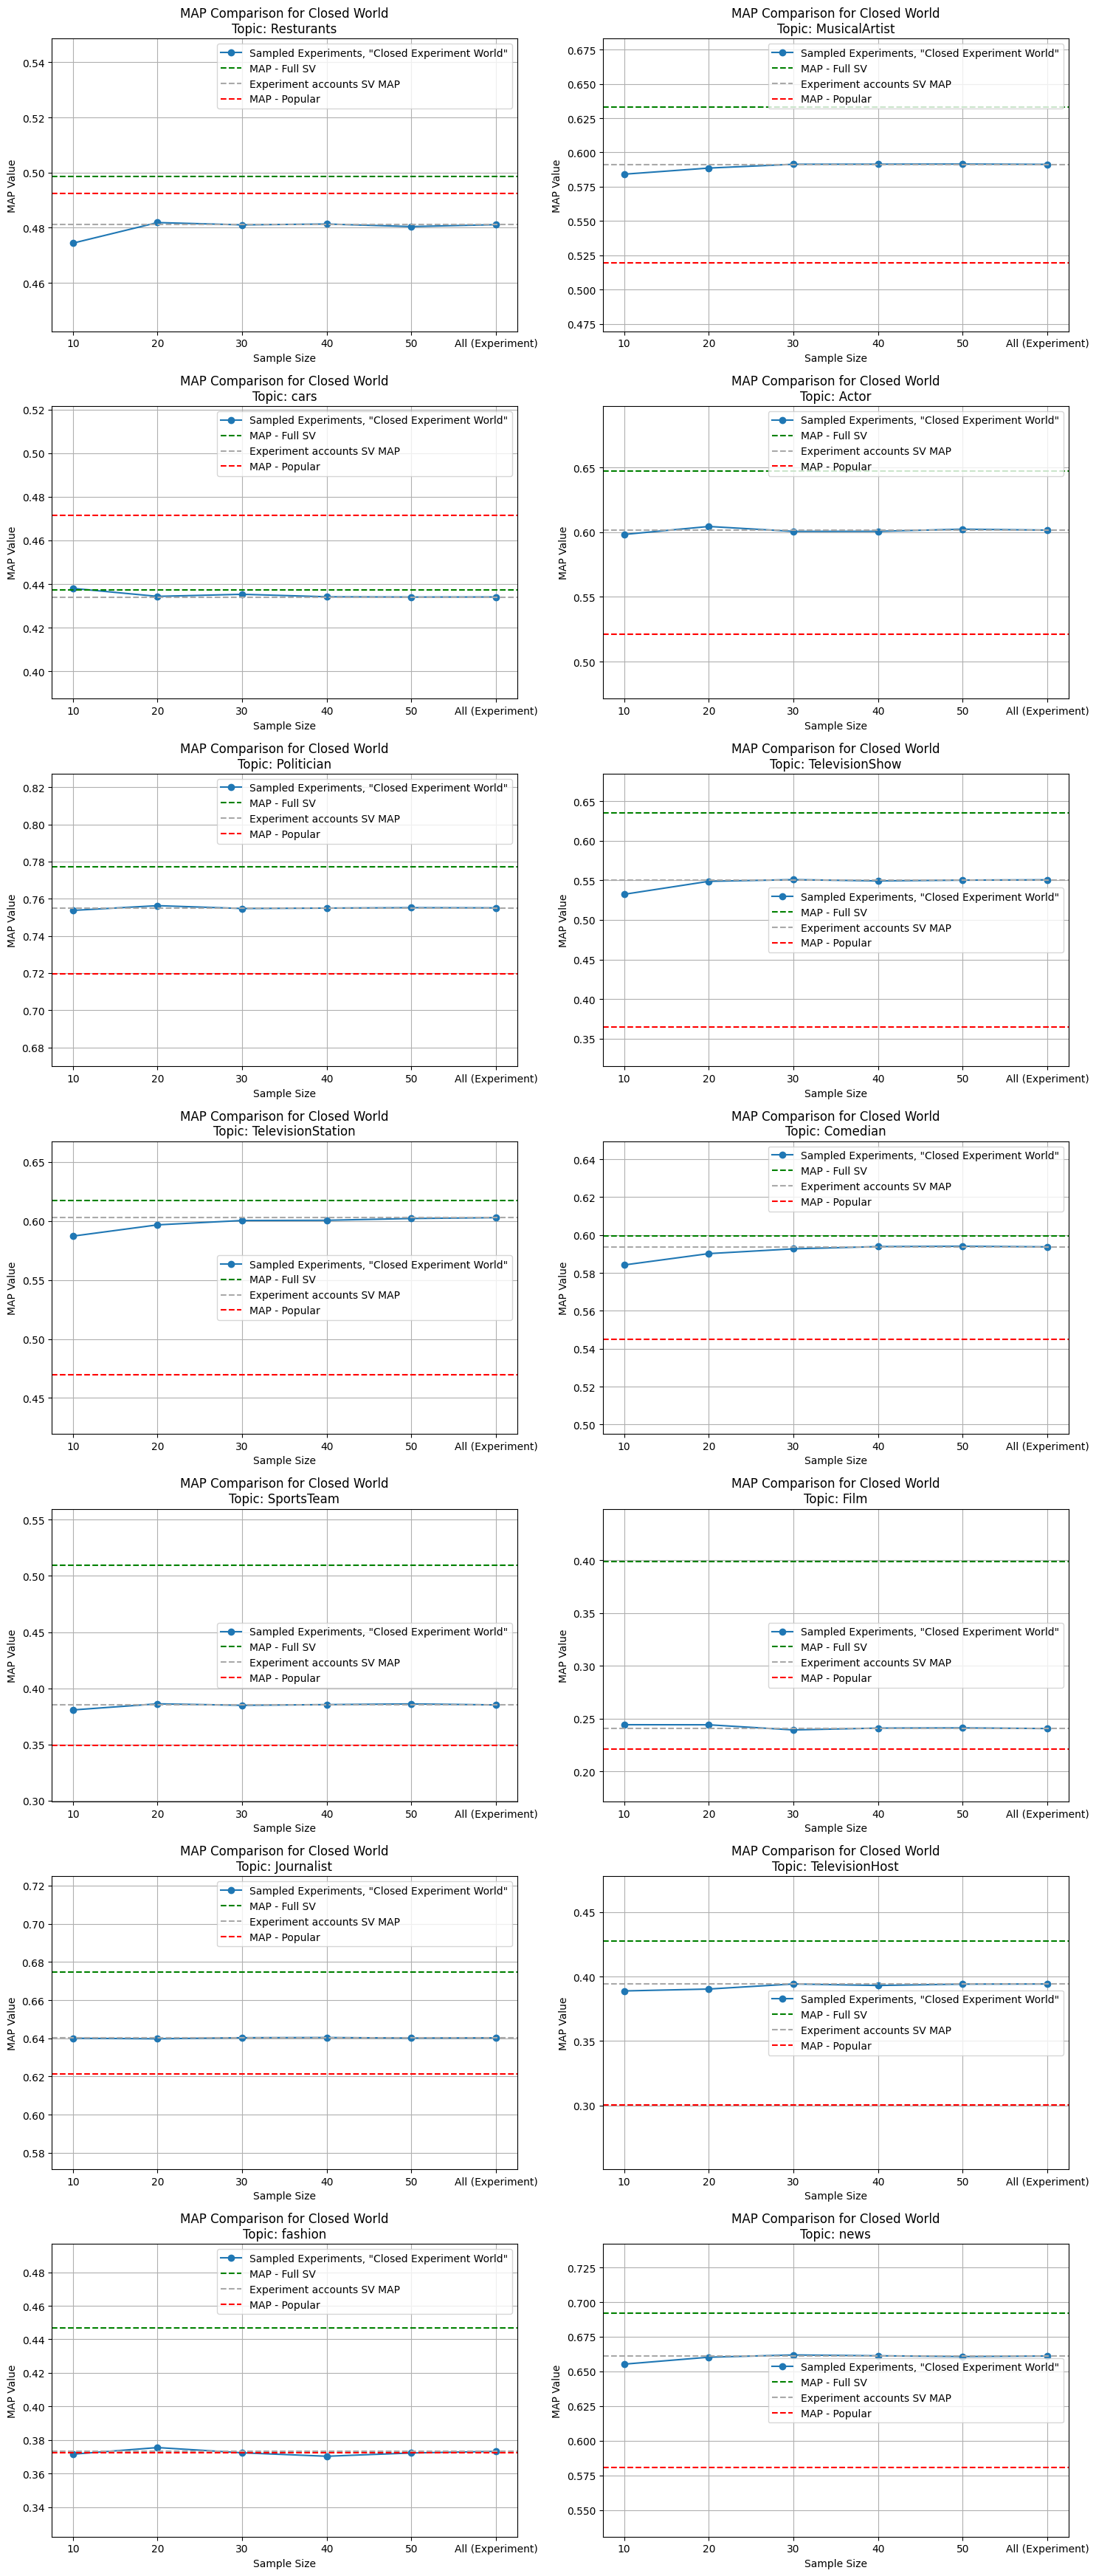

In [279]:
import matplotlib.pyplot as plt
import math

# 1. Determine layout size
num_topics = len(topic_list)
cols = 2  # You can change this to 3 if you want wider rows
rows = math.ceil(num_topics / cols)

# 2. Create the subplots
fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows))
axes = axes.flatten()  # Flatten the 2D array of axes for easy iteration

for i, selected_topic in enumerate(topic_list):
    ax = axes[i]
    
    # Get the data for the current topic
    row = threshold_restuls[threshold_restuls["topic"] == selected_topic].iloc[0]
    
    # Data preparation
    x_labels = ['10', '20', '30', '40', '50','All (Experiment)']
    y_values = [
        row['exp_sv_sample__10_map'],
        row['exp_sv_sample__20_map'],
        row['exp_sv_sample__30_map'],
        row['exp_sv_sample__40_map'],
        row['exp_sv_sample__50_map'],
        row['experimantsv_map'],
    ]
    
    # 3. Plotting on the specific subplot (ax)
    ax.plot(x_labels, y_values, marker='o', label='Sampled Experiments, "Closed Experiment World"')

    # Calculate Y limits based on your logic
    max_y = max(row['fullsv_map'], row['popular_map']) + 0.05
    min_y = min(row['fullsv_map'], row['popular_map']) - 0.05
    
    # Add horizontal lines
    ax.axhline(y=row['fullsv_map'], color='green', linestyle='--', label='MAP - Full SV')
    ax.axhline(y=row['experimantsv_map'], color='darkgray', linestyle='--', label='Experiment accounts SV MAP')
    ax.axhline(y=row['popular_map'], color='red', linestyle='--', label='MAP - Popular')
    
    # Styling the subplot
    ax.set_title(f"MAP Comparison for Closed World\nTopic: {selected_topic}")
    ax.set_xlabel("Sample Size")
    ax.set_ylabel("MAP Value")
    ax.set_ylim(min_y, max_y)
    ax.legend(loc='best')
    ax.grid(True)

# 4. Hide any unused subplots (if topic count is odd)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# 5. Final layout adjustments and save
plt.tight_layout()
plt.savefig('all_topics_comparison.png', dpi=300)
plt.show()

# Mean Average Precision (MAP) on All Accounts
* here we don't evaluate only the accounts in the experiment, but we show a growing trend on all accounts (excluding the category),
meaning we don't limit our 'world' for a cold start scenario

In [ ]:
# להוסיף ניסויים בקפיצות 
10,20,30,40,50,80,100,
להוציא את כלהחשבונות של הקטגוריה של הקטגוריה מחוץ למדגם
וגם את המקסימום
פשוט לא להגביל רק לחשבונות שנשארים בניסוי

להוציא גם טבלה וגם גרפים עם התוצאות.

לבדוק קורלציה בין קטגוריות (שמישהו שעוקב אחרי ספורט עוקב גם אחרי)
============
tsne על 20 musical artists ביחד עם עוד שתי קטגוריות
לנסות להראות שהם מתקבצים לא בהכרח לפי הנושא
cluster של ישויות מכל מני סוגים

===============
משתמשים מהניסוי שעשינו ולעשות להם ניבוי תכונות לפי - המשתמשים מהקובץ הזה
פרופיל של מי שעוקב אחרי משתמשים מסויימים (גיל, השכלה, מין)

כמו במאמר של ענבר אולי המפה הזאת

אלאניס מוריסט מול מדונה
ציר x זה הקטגוריות, ציר ה-y זה אחוז מהקטגוריה (אחוז נשים למשל)

In [ ]:

map_all_topics = pd.DataFrame()

for topic in (pbar := tqdm(topic_list)):
    #pbar.set_description(f"Preparing topic {topic}")
    #df_for_topic = prepare_df_for_topic(topic, df_users)
    df_for_topic = df_for_all_topic[topic]
    map_result = pd.DataFrame()

    for i, user in tqdm(df_for_topic.iterrows()):    

        pbar.set_description(f"Processing topic: {topic} user: {user['screen_name']}")
        user_all_accounts = list_str(user['friends_ids'])
        
        # All accounts that the user follows except the ones from the topic...
        user_all_accounts_except_selected_accounts = list( set(user_all_accounts) - set(user['topic_accounts_str']) )
        
        # Get SV rank when using all of the accounts that the user follows
        all_sv_rank = get_sv_rank(sv.get_average_embeddings(user_all_accounts_except_selected_accounts)[0],all_topics[topic])
        all_sv_rank = reset_and_rank_topic_accounts(all_sv_rank, user['topic_accounts'])
        
        # Try differet thresholds of 
        sample_result_data = {}
        for sample_size in [10, 20, 30, 40, 50, 80, 100, 300, 500, 5000]:
            if sample_size < len(user_all_accounts_except_selected_accounts):
                random.seed(76)
                acounts_for_sample = random.sample(user_all_accounts_except_selected_accounts,sample_size)
            else:
                acounts_for_sample = user_all_accounts_except_selected_accounts
                
            sample_sv_rank = get_sv_rank(sv.get_average_embeddings(list_str(acounts_for_sample))[0],all_topics[topic])
            sample_sv_rank = reset_and_rank_topic_accounts(sample_sv_rank, user['topic_accounts'])
            sample_result_data[f"exp_sv_sample__{sample_size}_map"]= [(sample_sv_rank['index'] / sample_sv_rank['rank']).mean()]
        
        # Get popularity rank
        user_popular_rank = get_popular_rank(all_topics[topic])
        user_popular_rank = reset_and_rank_topic_accounts(user_popular_rank, user['topic_accounts'])

        result_dict = {'user':[user['screen_name']],
                                         'fullsv_rank':[all_sv_rank['rank'].values],
                                         'fullsv_map':[(all_sv_rank['index'] / all_sv_rank['rank']).mean()],
#                                         'experimantsv_rank':[non_topic_accounts_sv_rank['rank'].values],
#                                         'experimantsv_map':[(non_topic_accounts_sv_rank['index'] / non_topic_accounts_sv_rank['rank']).mean()],
                                         'popular_rank': [user_popular_rank['rank'].values],
                                         'popular_map':[( user_popular_rank['index'] / user_popular_rank['rank']).mean()]
                                        }
        
        result = pd.DataFrame.from_dict(result_dict | sample_result_data)
        map_result = pd.concat([map_result,result])

    map_result['topic'] = topic
    map_all_topics = pd.concat([map_all_topics,map_result])


In [138]:
columns_to_show = [col for col in map_result.columns if 'map' in col]
threshold_restuls = map_all_topics[['topic']+columns_to_show].groupby(by='topic').mean().reset_index()
threshold_restuls

,topic,fullsv_map,popular_map,exp_sv_sample__10_map,exp_sv_sample__20_map,exp_sv_sample__30_map,exp_sv_sample__40_map,exp_sv_sample__50_map,exp_sv_sample__80_map,exp_sv_sample__100_map,exp_sv_sample__300_map,exp_sv_sample__500_map,exp_sv_sample__5000_map
0,Actor,0.647,0.521,0.609,0.623,0.632,0.635,0.637,0.641,0.642,0.648,0.649,0.647
1,Comedian,0.599,0.545,0.573,0.581,0.587,0.591,0.593,0.597,0.599,0.601,0.598,0.599
2,Film,0.399,0.221,0.341,0.356,0.368,0.375,0.372,0.393,0.398,0.397,0.401,0.399
3,Journalist,0.675,0.622,0.641,0.655,0.663,0.665,0.668,0.670,0.671,0.672,0.674,0.675
4,MusicalArtist,0.633,0.520,0.603,0.613,0.622,0.628,0.625,0.629,0.629,0.633,0.632,0.633
5,Politician,0.777,0.720,0.753,0.764,0.769,0.769,0.774,0.774,0.776,0.777,0.777,0.777
6,Resturants,0.499,0.492,0.470,0.485,0.482,0.485,0.485,0.490,0.490,0.496,0.496,0.499
7,SportsTeam,0.510,0.349,0.463,0.471,0.484,0.493,0.495,0.503,0.506,0.509,0.510,0.510
8,TelevisionHost,0.428,0.301,0.379,0.414,0.416,0.426,0.422,0.425,0.422,0.427,0.431,0.428
9,TelevisionShow,0.635,0.365,0.566,0.597,0.612,0.618,0.622,0.625,0.624,0.631,0.635,0.635


# Previous Graph

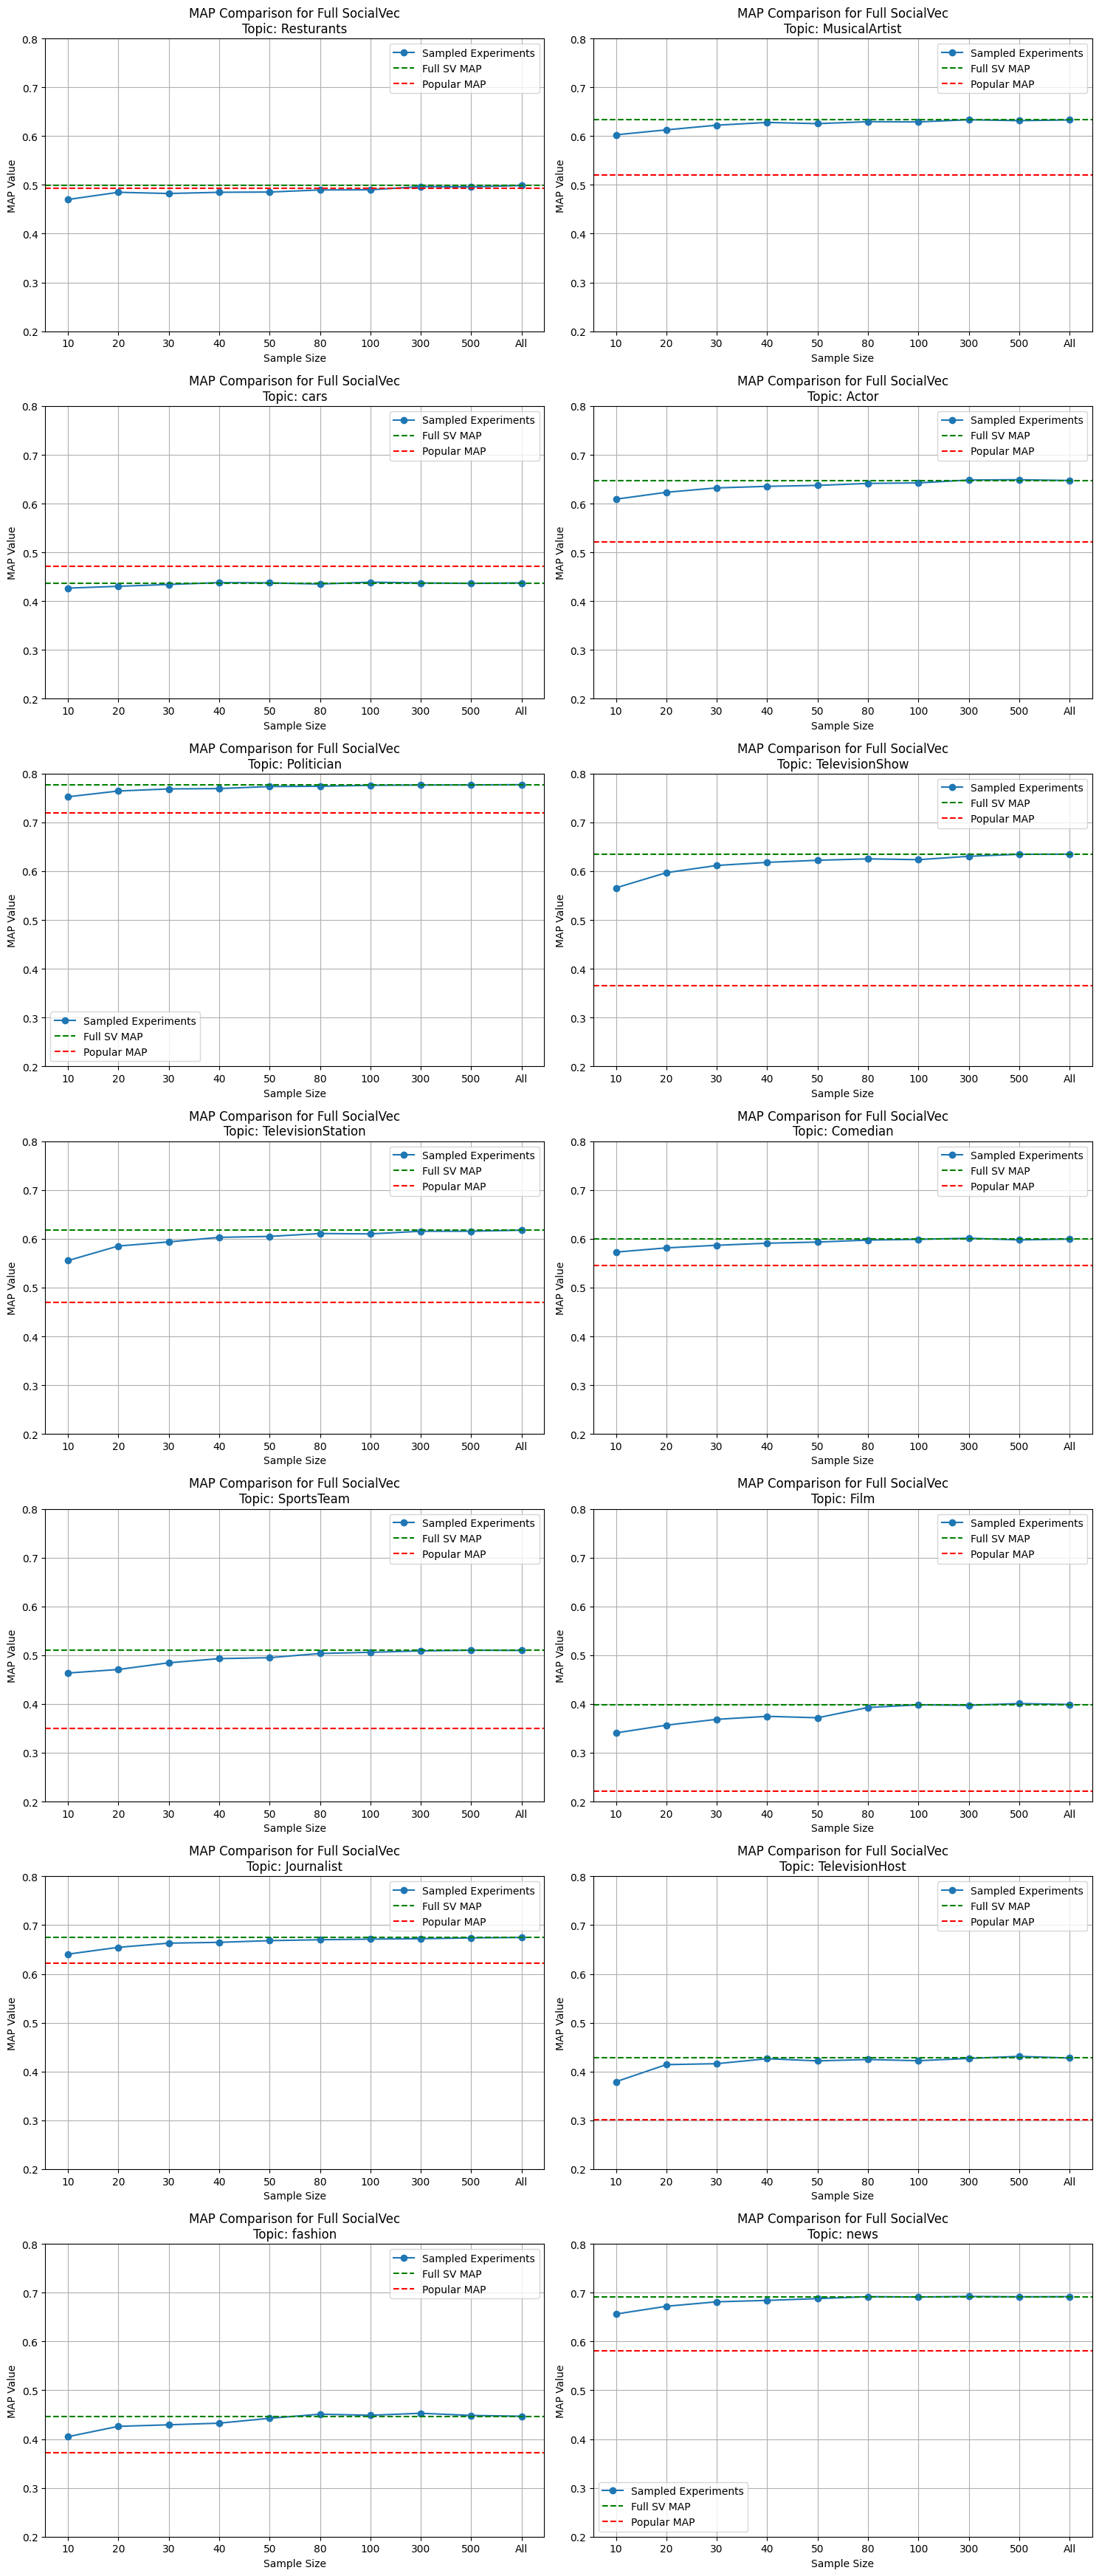

In [188]:
import matplotlib.pyplot as plt
import math

columns_to_show = [col for col in map_result.columns if 'map' in col]
threshold_restuls = map_all_topics[['topic']+columns_to_show].groupby(by='topic').mean().reset_index()


# 1. Determine layout size
num_topics = len(topic_list)
cols = 2  # You can change this to 3 if you want wider rows
rows = math.ceil(num_topics / cols)

# 2. Create the subplots
fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows))
axes = axes.flatten()  # Flatten the 2D array of axes for easy iteration

for i, selected_topic in enumerate(topic_list):
    ax = axes[i]
    
    # Get the data for the current topic
    row = threshold_restuls[threshold_restuls["topic"] == selected_topic].iloc[0]
    
    # Data preparation
    x_labels = ['10', '20', '30', '40', '50', '80', '100', '300', '500', '5000']
    y_values = [row[f'exp_sv_sample__{value}_map'] for value in x_labels]
    x_labels[-1] = 'All'
    x_labels
    
    
    # 3. Plotting on the specific subplot (ax)
    ax.plot(x_labels, y_values, marker='o', label='Sampled Experiments')

    # Calculate Y limits based on your logic
    max_y = 0.8#= max(row['fullsv_map'], row['popular_map']) + 0.05
    min_y = 0.2#= min(row['fullsv_map'], row['popular_map']) - 0.05
    
    # Add horizontal lines
    ax.axhline(y=row['fullsv_map'], color='green', linestyle='--', label='Full SV MAP')
    ax.axhline(y=row['popular_map'], color='red', linestyle='--', label='Popular MAP')
    
    # Styling the subplot
    ax.set_title(f"MAP Comparison for Full SocialVec\nTopic: {selected_topic}")
    ax.set_xlabel("Sample Size")
    ax.set_ylabel("MAP Value")
    ax.set_ylim(min_y, max_y)
    ax.legend(loc='best')
    ax.grid(True)

# 4. Hide any unused subplots (if topic count is odd)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# 5. Final layout adjustments and save
plt.tight_layout()
plt.savefig('all_topics_comparison2.png', dpi=300)
plt.show()



## legend text:
# - Popularity Baseline
# - Social Embedding: All (SE1)
# - Social Embedding: Selected Accounts (SE2)
# - SE1: Sampling 
# - SE2: Sampling

# TSNE reflection

# Generate data for Tensorboard Embeddings Projector

In [34]:
import csv
import os
import numpy as np

# Define output paths
output_dir = 'outputs'
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

vectors_path = os.path.join(output_dir, 'vectors.tsv')
metadata_path = os.path.join(output_dir, 'metadata.tsv')

with open(vectors_path, 'w', newline='', encoding='utf-8') as vec_file, \
     open(metadata_path, 'w', newline='', encoding='utf-8') as meta_file:
    
    vec_writer = csv.writer(vec_file, delimiter='\t')
    meta_writer = csv.writer(meta_file, delimiter='\t')
    
    # Write metadata header
    meta_writer.writerow(['Topic', 'Twitter Screen Name', 'Twitter Name'])
    
    count = 0
    for topic in all_topics:
        df = all_topics[topic]
        
        # Check if required columns exist
        if 'account_sv' not in df.columns:
            print(f"Skipping topic {topic}: 'account_sv' column missing")
            continue
            
        for _, row in df.iterrows():
            embedding = row['account_sv']
            
            # Ensure embedding is a valid numpy array of length 100
            if isinstance(embedding, np.ndarray) and len(embedding) == 100:
                # Write embedding vector
                vec_writer.writerow(embedding)
                
                # Get metadata fields
                screen_name = row.get('twitter_screen_name', '')
                # Try to find name, default to empty string if not found
                name = row.get('twitter_name', row.get('name', ''))
                
                # Write metadata
                meta_writer.writerow([topic, screen_name, name])
                count += 1

print(f"Successfully generated TensorBoard files with {count} embeddings.")
print(f"Vectors file: {vectors_path}")
print(f"Metadata file: {metadata_path}")

Successfully generated TensorBoard files with 276 embeddings.
Vectors file: outputs/vectors.tsv
Metadata file: outputs/metadata.tsv


# Attributes of the users in the experiment

In [171]:
def count_matches(row_list, comparison_set):
    return len(set(row_list).intersection(comparison_set))

In [189]:
current_topic = 'fashion'

account_list_int = [int(x) for x in df_for_all_topic[current_topic].head(20)['user_id'].values]

In [190]:
accounts_set = set(account_list_int)

df_users_with_attributes['match_count'] = df_users_with_attributes['friends_ids'].apply(lambda x: count_matches(x, accounts_set))

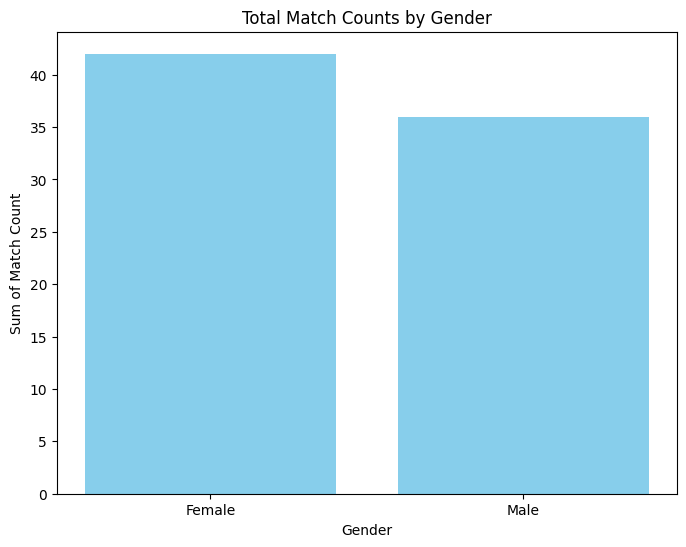

In [192]:
import pandas as pd
import matplotlib.pyplot as plt

# ... (Assuming df_users_with_attributes is already loaded) ...

# 1. Filter
clean_df = df_users_with_attributes.dropna(subset=['gender_prediction'])
clean_df = clean_df[clean_df['gender_label'] != 'Unknown']

# 2. Group
grouped_df = clean_df.groupby('gender_label')['match_count'].sum().reset_index()

# 3. Plot
plt.figure(figsize=(8, 6))

# We store the bar container to ensure x-axis alignment
bars = plt.bar(grouped_df['gender_label'], grouped_df['match_count'], color='skyblue')

# --- THE FIX ---
# Explicitly tell Matplotlib to use the gender names as labels for the x-axis positions
plt.xticks(
    ticks=range(len(grouped_df)),                # The positions (0, 1, 2...)
    labels=grouped_df['gender_label'],      # The names ('Male', 'Female'...)
    rotation=0                                   # Set to 45 if labels overlap
)
# ---------------

plt.xlabel('Gender')
plt.ylabel('Sum of Match Count')
plt.title('Total Match Counts by Gender')

plt.show()

# Classifier 2020c

In [250]:
sv_cls = SocialVec("2020c")

#init the classifier
sv_cls.init_classifier()

✅  Initializing Model
✅  Load Metadata


In [251]:
def check_classifier(single_user, expected_class, classifier_name):
    user = sv_cls.get_average_embeddings([sv_cls.get_userid(single_user)])[0]
    prediction = sv_cls.classifier.predict(classifier_name, user)
    if prediction[0] == expected_class:
        print(f"TEST PASSED. Expected: {expected_class}, Got: {prediction[0]}, confidence: {prediction[1]}")
    else:
        print(f"FAILED! Expected: {expected_class}, Got: {prediction[0]}, confidence: {prediction[1]}")


In [252]:
check_classifier("BarackObama", "Democrat", "political")
check_classifier("ChickfilA", "Republican", "political")
check_classifier("RapSheet", "Male", "gender")
check_classifier("ChelseaHouska", "Female", "gender")
check_classifier("RASHEEDA", "AfrAmerican", "ethnicity")
check_classifier("Country_Words", "Caucasian", "ethnicity")
check_classifier("NASA", "Degree", "education")
check_classifier("illuminatihotts", "HighSchool", "education")
check_classifier("ToysRUs", "Yes", "children")
check_classifier("donaldglover", "No", "children")

TEST PASSED. Expected: Democrat, Got: Democrat, confidence: 0.9980640703579411
TEST PASSED. Expected: Republican, Got: Republican, confidence: 0.9834940433502197
TEST PASSED. Expected: Male, Got: Male, confidence: 0.9999228715896606
TEST PASSED. Expected: Female, Got: Female, confidence: 0.9999999816693634
TEST PASSED. Expected: AfrAmerican, Got: AfrAmerican, confidence: 0.9999979927467848
TEST PASSED. Expected: Caucasian, Got: Caucasian, confidence: 0.999997615814209
TEST PASSED. Expected: Degree, Got: Degree, confidence: 0.8461308479309082
TEST PASSED. Expected: HighSchool, Got: HighSchool, confidence: 0.16317451000213623
TEST PASSED. Expected: Yes, Got: Yes, confidence: 0.9179730415344238
TEST PASSED. Expected: No, Got: No, confidence: 0.994706769939512


In [253]:
classifier_name_list = ["political", "gender", "ethnicity", "education", "children", "age"]

In [254]:
df_subset = df_users.copy()

In [255]:
for idx, user in tqdm(df_subset.iterrows(),total=df_subset.shape[0]):
    for classifier_name in classifier_name_list:
        emb, sv_len = sv_cls.get_average_embeddings(user['friends_ids'])
        cls = sv_cls.classifier.predict(classifier_name, emb)
        df_subset.at[idx, "SocialVec_len"] = sv_len
        df_subset.at[idx, classifier_name] = cls[0]
        df_subset.at[idx, f"{classifier_name}_proba"] = cls[1]


  0%|          | 0/11153 [00:00<?, ?it/s]

In [283]:
#df_subset[df_subset['topic']=='SportsTeam']['age'].value_counts()

Under25    527
Over25     164
Name: age, dtype: int64

### Create seperate line per account that we check

In [430]:
df_exploded = df_subset.explode('experiment_accounts')
#df_exploded = df_exploded.reset_index(drop=True)

### Create dataframe with account_id to account_name mapping

In [431]:
experiment_accounts_df = pd.DataFrame({"account_id":df_exploded['experiment_accounts'].unique()})
experiment_accounts_df['account_id'] = experiment_accounts_df['account_id'].astype(int)
experiment_accounts_df['account_name'] = experiment_accounts_df['account_id'].apply(lambda x: sv_cls.get_screen_name(x))

In [432]:
df_exploded = pd.merge(df_exploded, experiment_accounts_df, left_on='experiment_accounts', right_on='account_id')

In [433]:
account_count_in_exploded = df_exploded.groupby(by=['account_name']).count()

In [ ]:
account_to_check = 'nautica'

df_exploded[df_exploded['account_name']==account_to_check].XXX.value_counts()

Male      64
Female    45
Name: gender, dtype: int64

## Find Accounts with Extreme Value Count Ratios

For each topic (political, gender, ethnicity, education, children), find 4 accounts where the distribution is most extreme (one category dominates)

In [ ]:
def calculate_extreme_ratio(value_counts):
    """
    Calculate how extreme a distribution is by taking the ratio of the most common value
    to the sum of all other values. Higher ratio means more extreme.
    """
    if len(value_counts) < 2:
        return float('inf')  # If only one category, it's maximally extreme
    
    most_common = value_counts.iloc[0]
    rest_sum = value_counts.iloc[1:].sum()
    
    if rest_sum == 0:
        return float('inf')
    
    return most_common / rest_sum

# Topics to analyze
topics = ['political', 'gender', 'ethnicity', 'education', 'children']

# Store results
extreme_accounts_results = {}

for topic in topics:
    print(f"\n{'='*70}")
    print(f"Analyzing topic: {topic.upper()}")
    print(f"{'='*70}")
    
    unique_accounts = df_exploded['account_name'].unique()
    account_ratios = []
    
    for account in unique_accounts:
        account_data = df_exploded[df_exploded['account_name'] == account][topic].value_counts()
        
        # Only consider accounts with data for this topic
        if len(account_data) > 0:
            extreme_ratio = calculate_extreme_ratio(account_data)
            account_ratios.append({
                'account_name': account,
                'extreme_ratio': extreme_ratio,
                'value_counts': account_data,
                'total_count': account_data.sum(),
                'dominant_category': account_data.index[0] if len(account_data) > 0 else None,
                'dominant_percentage': (account_data.iloc[0] / account_data.sum() * 100) if len(account_data) > 0 else 0
            })
    
    # Group accounts by dominant category
    from collections import defaultdict
    category_groups = defaultdict(list)
    
    for account in account_ratios:
        category_groups[account['dominant_category']].append(account)
    
    # Sort each category group by extreme ratio and get top 5
    extreme_accounts_results[topic] = {}
    
    for category, accounts in category_groups.items():
        # Sort by extreme ratio (descending) and get top 5
        accounts_sorted = sorted(accounts, key=lambda x: x['extreme_ratio'], reverse=True)[:5]
        extreme_accounts_results[topic][category] = accounts_sorted
        
        # Display results
        print(f"\n{'-'*70}")
        print(f"Top 5 accounts with '{category}' as dominant category:\n")
        for i, result in enumerate(accounts_sorted, 1):
            print(f"{i}. {result['account_name']}")
            print(f"   Dominant Category: {result['dominant_category']} ({result['dominant_percentage']:.1f}%)")
            print(f"   Extreme Ratio: {result['extreme_ratio']:.2f}")
            print(f"   Total samples: {result['total_count']}")
            print(f"   Distribution:")
            for cat, count in result['value_counts'].items():
                percentage = (count / result['total_count'] * 100)
                print(f"      {cat}: {count} ({percentage:.1f}%)")
            print()

## Radar Charts: Account Demographics vs Population Baseline

Create spider/radar graphs showing the demographic profile of extreme accounts compared to the overall population

# Modified calculation of ratio

In [259]:
sampled_accounts = ['ChickfilA', 'NineWest', 'DeerGear', 
                    'ArianaGrande', 'celtics', 'SnoopDogg',
                    'Bugatti','TheDailyShow', 'SarahKSilverman',]

## Updated spider graph

In [260]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from math import pi
import math

def create_demographic_radar_grid(df, account_pairs, charts_per_row=2, account_col='account_selected_for'):
    """
    Generates a grid of radar charts comparing pairs of accounts.
    
    Parameters:
    - df: The pandas DataFrame containing the data.
    - account_pairs: A list of tuples, e.g., [('McDonalds', 'ChickfilA'), ('McDonalds', 'BurgerKing')]
    - charts_per_row: Integer, number of charts to display in a single row.
    - account_col: The column name for the account identifier.
    """
    
    # 1. Define metrics and targets
    metrics = {
        'political': 'Democrat',
        'gender': 'Female',
        'ethnicity': 'Caucasian', 
        'education': 'Degree',
        'age': 'Under25',
    }
    
    # Helper to calculate ratios
    def get_ratios(account_name):
        subset = df[df[account_col] == account_name]
        if subset.empty:
            return [0] * len(metrics)
        
        ratios = []
        for col, target in metrics.items():
            # Handle potential missing columns gracefully
            if col not in subset.columns:
                ratios.append(0)
                continue
            
            # clean whitespace just in case
            try:
                col_data = subset[col].astype(str).str.strip()
                count = (col_data == target).sum()
                total = len(subset)
                ratios.append(count / total if total > 0 else 0)
            except Exception:
                ratios.append(0)
        return ratios

    # 2. Setup Grid
    num_plots = len(account_pairs)
    num_rows = math.ceil(num_plots / charts_per_row)
    
    # Calculate angles
    N = len(metrics)
    angles = [n / float(N) * 2 * pi for n in range(N)]
    angles += angles[:1]
    
    # Labels for the axes
    labels = [f"{k.capitalize()}\n({v})" for k, v in metrics.items()]
    
    # Create Figure
    fig = plt.figure(figsize=(6 * charts_per_row, 6 * num_rows))
    
    for idx, (acc1, acc2) in enumerate(account_pairs):
        # Add subplot with polar projection
        ax = fig.add_subplot(num_rows, charts_per_row, idx + 1, polar=True)
        
        # Get data
        values1 = get_ratios(acc1)
        values2 = get_ratios(acc2)
        
        # Close the loop
        values1 += values1[:1]
        values2 += values2[:1]
        
        # Plot acc1
        ax.plot(angles, values1, 'o', linewidth=2, linestyle='-', label=acc1, color='#1f77b4')
        ax.fill(angles, values1, alpha=0.15, color='#1f77b4')
        
        # Plot acc2
        ax.plot(angles, values2, 'o', linewidth=2, linestyle='--', label=acc2, color='#d62728')
        ax.fill(angles, values2, alpha=0.1, color='#d62728')
        
        # Formatting
        plt.xticks(angles[:-1], labels, color='grey', size=8)
        ax.set_rlabel_position(0)
        plt.yticks([0.2, 0.4, 0.6, 0.8], ["20%", "40%", "60%", "80%"], color="grey", size=7)
        plt.ylim(0, 1)
        
        plt.title(f"{acc1} vs {acc2}", size=11, y=1.1)
        plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize='small')

    plt.tight_layout()
    plt.savefig('radar_grid.png', bbox_inches='tight')


In [385]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from math import pi
import math

def create_demographic_radar_grid(df, account_groups, charts_per_row=2, account_col='account_selected_for',filename_prefix=''):
    """
    Generates a grid of radar charts comparing groups of accounts.
    
    Parameters:
    - df: The pandas DataFrame containing the data.
    - account_groups: A list of lists/tuples, e.g., [('McDonalds', 'ChickfilA', 'BurgerKing'), ('Starbucks', 'Dunkin')]
    - charts_per_row: Integer, number of charts to display in a single row.
    - account_col: The column name for the account identifier.
    """
    
    # 1. Define metrics and targets
    metrics = {
        'political': 'Democrat',
        'gender': 'Female',
        'ethnicity': 'Caucasian', 
        'education': 'Degree',
        'age': 'Under25',
    }
    
    # Color palette for up to 6 accounts per graph
    colors = ['#1f77b4', '#d62728', '#2ca02c', '#ff7f0e', '#9467bd', '#8c564b']

    # Helper to calculate ratios
    def get_ratios(account_name):
        subset = df[df[account_col] == account_name]
        if subset.empty:
            return [0] * len(metrics)
        
        ratios = []
        for col, target in metrics.items():
            if col not in subset.columns:
                ratios.append(0)
                continue
            
            try:
                col_data = subset[col].astype(str).str.strip()
                count = (col_data == target).sum()
                total = len(subset)
                ratios.append(count / total if total > 0 else 0)
            except Exception:
                ratios.append(0)
        return ratios

    # 2. Setup Grid
    num_plots = len(account_groups)
    num_rows = math.ceil(num_plots / charts_per_row)
    
    # Calculate angles
    N = len(metrics)
    angles = [n / float(N) * 2 * pi for n in range(N)]
    angles += angles[:1]
    
    labels = [f"{k.capitalize()}\n({v})" for k, v in metrics.items()]
    
    # Create Figure
    fig = plt.figure(figsize=(8 * charts_per_row, 7 * num_rows))
    
    for idx, group in enumerate(account_groups):
        ax = fig.add_subplot(num_rows, charts_per_row, idx + 1, polar=True)
        
        # Iterate through each account in the group
        for i, account_name in enumerate(group):
            if i >= len(colors): break  # Limit to 6 colors
            
            values = get_ratios(account_name)
            values += values[:1]  # Close the loop
            
            num_of_followers = df[df[account_col] == account_name].shape[0]

            account_label = all_topics[topic][all_topics[topic]['twitter_screen_name']==account_name].iloc[0]['twitter_name']
            
            account_label = f"{account_label} (N={num_of_followers})"
            
            # Plot and Fill
            ax.plot(angles, values, 'o', linewidth=2, linestyle='-', 
                    label=account_label, color=colors[i])
            ax.fill(angles, values, alpha=0.1, color=colors[i])

        # show the average of the topic
        

        
        # Formatting
        plt.xticks(angles[:-1], labels, color='grey', size=9)
        ax.set_rlabel_position(0)
        plt.yticks([0.2, 0.4, 0.6, 0.8], ["20%", "40%", "60%", "80%"], color="grey", size=8)
        plt.ylim(0, 1)
        
        # Dynamic Title
        title_text = " vs ".join([all_topics[topic][all_topics[topic]['twitter_screen_name']==acc].iloc[0]['twitter_name'] for acc in group])
        plt.title(f"Comparison: {title_text}", size=12, y=1.1, fontweight='bold')
        plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize='small')

    plt.tight_layout()
    plt.savefig(f'radar_plots/{filename_prefix}_radar_grid.png', bbox_inches='tight')
    plt.show()

In [265]:
def chunk_accounts(account_list, group_size=4):
    """
    Splits a flat list of accounts into groups of a specific size.
    Each account appears exactly once.
    """
    # Create groups using list slicing
    return [account_list[i:i + group_size] for i in range(0, len(account_list), group_size)]

In [434]:
del df_exploded

In [437]:
account_count_in_exploded.reset_index(inplace=True)

,account_name,tweet_id
14,ArianaGrande,2546
186,cher,2456
215,kanyewest,2600
217,kendricklamar,1876
255,taylorswift13,3318


/tmp/ipykernel_2828161/608367533.py:38: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "" (-> linestyle='-'). The keyword argument will take precedence.
  ax.plot(angles, values, marker, color=color, linewidth=2, label=label, linestyle=linestyle)


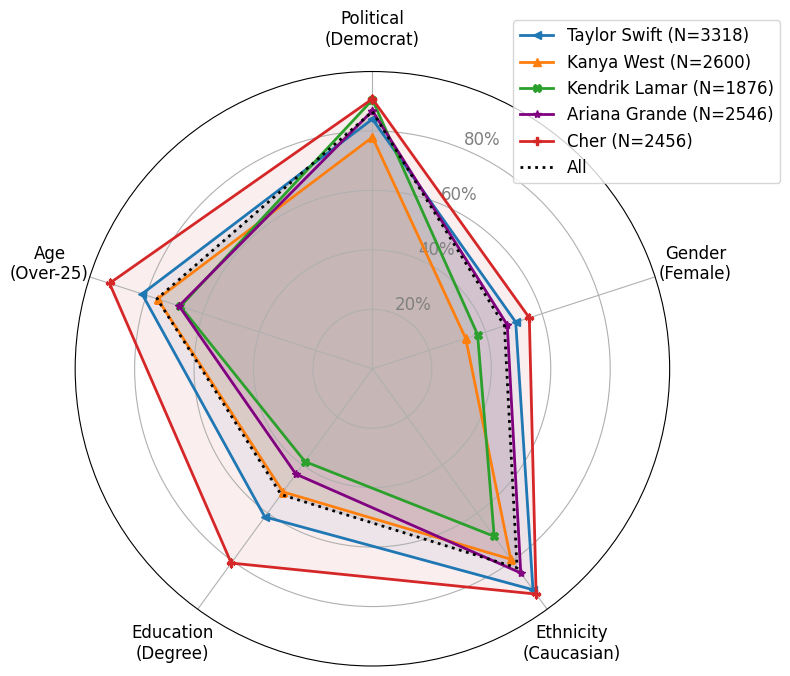

In [ ]:
for topic in topic_list:
    account_groups = chunk_accounts(accounts_to_show, group_size=5)
    create_demographic_radar_grid(df_exploded, account_groups, charts_per_row=2, filename_prefix=topic)

In [544]:
columns_to_save = ['user_id','screen_name','number_of_categories_this_user_follows','topic','account_name', 'SocialVec_len', 'political', 'political_proba', 'gender',
       'gender_proba', 'ethnicity', 'ethnicity_proba', 'education',
       'education_proba', 'children', 'children_proba', 'account_id',
        'age', 'age_proba']

In [565]:
cols_to_count = ['political', 'gender', 'ethnicity', 'education', 'children', 'age']
df_encoded = pd.get_dummies(df_exploded, columns=cols_to_count, prefix_sep='_')

/tmp/ipykernel_411/3310549230.py:3: FutureWarning: The default value of numeric_only in DataFrameGroupBy.sum is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  cat_count = df_encoded.groupby(['topic', 'account_name']).sum().reset_index()


In [586]:
cat_count = df_encoded.groupby(['account_name']).sum().reset_index()

/tmp/ipykernel_411/1794522843.py:1: FutureWarning: The default value of numeric_only in DataFrameGroupBy.sum is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  cat_count = df_encoded.groupby(['account_name']).sum().reset_index()


In [588]:
cat_count[['account_name','political_Democrat',
       'political_Republican', 'gender_Female', 'gender_Male',
       'ethnicity_AfrAmerican', 'ethnicity_Caucasian', 'education_Degree',
       'education_HighSchool', 'children_No', 'children_Yes', 'age_Over25',
       'age_Under25']].sample(10)

,account_name,political_Democrat,political_Republican,gender_Female,gender_Male,ethnicity_AfrAmerican,ethnicity_Caucasian,education_Degree,education_HighSchool,children_No,children_Yes,age_Over25,age_Under25
81,HuntsmanAbby,223,145,116,252,15,353,31,337,345,23,8,360
82,IngrahamAngle,605,900,339,1166,38,1467,174,1331,1405,100,32,1473
6,Acosta,3454,408,1544,2318,186,3676,281,3581,3385,477,94,3768
258,theestallion,1292,147,720,719,484,955,928,511,1422,17,529,910
163,Toyota,349,195,168,376,58,486,239,305,506,38,40,504
248,selenagomez,1895,358,1141,1112,281,1972,1256,997,2211,42,654,1599
114,Morning_Joe,1464,194,612,1046,74,1584,88,1570,1449,209,30,1628
200,etnow,904,223,665,462,126,1001,432,695,1097,30,140,987
98,LACOSTE,177,32,119,90,46,163,102,107,205,4,31,178
79,Hooters,116,111,61,166,13,214,140,87,211,16,26,201


In [590]:
cat_count.columns

Index(['account_name', 'followers_count', 'friends_ids_len',
       'number_of_accounts_full_sv', 'number_of_accounts_from_experiment',
       'number_of_categories_this_user_follows', 'SocialVec_len',
       'political_proba', 'gender_proba', 'ethnicity_proba', 'education_proba',
       'children_proba', 'account_id', 'age_proba', 'political_Democrat',
       'political_Republican', 'gender_Female', 'gender_Male',
       'ethnicity_AfrAmerican', 'ethnicity_Caucasian', 'education_Degree',
       'education_HighSchool', 'children_No', 'children_Yes', 'age_Over25',
       'age_Under25'],
      dtype='object')

In [580]:
cat_count.drop(columns=['topic'],inplace=True)

In [581]:
all_topics_concatednated_df = pd.DataFrame()

for topic in topic_list:
    local_df = all_topics[topic][['twitter_screen_name']].copy()
    local_df['topic'] = topic
    all_topics_concatednated_df = pd.concat([all_topics_concatednated_df,local_df])

In [592]:
pd.merge(all_topics_concatednated_df, cat_count, left_on = 'twitter_screen_name', right_on = 'account_name')[['topic','account_name','political_Democrat',
       'political_Republican', 'gender_Female', 'gender_Male',
       'ethnicity_AfrAmerican', 'ethnicity_Caucasian', 'education_Degree',
       'education_HighSchool', 'children_No', 'children_Yes', 'age_Over25',
       'age_Under25']].to_csv('accounts_with_attributes_stats.csv')

# Rate the accounts by LLM

For each account we use the same sample of 50 accounts for which we will get the names and provide them to the LLM (to be as fair as the SocialVec)

In [507]:
def get_name(x):
    try:
        return sv_cls.entities[sv_cls.entities['twitter_id']==x]['name'].iloc[0]
    except:
        return

### LLM Recommender Class

In [554]:
import dspy
import os
from dotenv import load_dotenv

# Load secrets from .env file
load_dotenv()

# For Azure OpenAI, we load these from environment variables
api_key = os.getenv("AZURE_OPENAI_API_KEY")
endpoint_url = os.getenv("AZURE_OPENAI_ENDPOINT")
openai_api_version = os.getenv("AZURE_OPENAI_API_VERSION")

lm = dspy.LM(
#    'azure/gpt-4o',
    api_key= api_key,
    api_base= endpoint_url,
    api_version= openai_api_version,
    model='azure/gpt-4o'
)
dspy.configure(lm=lm)
dspy.settings.configure(lm=lm)

class TwitterRecommendation(dspy.Signature):
    """
    given the below Twitter user, to which we provide a sampled list of accounts the user already follows, and a list of possible accounts to recommend for the user to follow, create a prioritized recommendation list.
    You must rank the entire list provided to you. 
    Try to deduce what you think the user might like based on the list of accounts they already follow.
    Return ONLY a valid list object with the ranked account twitter_user_id sorted by relevance (highest to lowest). Do not include name or reasoning.
    Example format: [71026122, 141341662, 567562934, ...]
    """
    
    followed_accounts = dspy.InputField(desc="Sampled list of other accounts the user already follows")
    potential_accounts = dspy.InputField(desc="JSON list of potential accounts to recommend with twitter_user_id and names")
    ranked_ids = dspy.OutputField(desc="list with the account twitter_user_id sorted by priority as a ranked key")

class Recommender(dspy.Module):
    def __init__(self):
        super().__init__()
        self.generate_ranking = dspy.Predict(TwitterRecommendation)
    
    def forward(self, followed_accounts, potential_accounts):
        return self.generate_ranking(
            followed_accounts=followed_accounts,
            potential_accounts=potential_accounts
    )

recommender = Recommender()


### For each user in the df_for_all_topic:
* sample the same 50 accounts as for SocialVec and create a string with the name of accounts the user follows.
* The names are of the accounts that exist in SV (which are the popular account of the sample of 50)

In [753]:
accounts_for_llm = pd.DataFrame()

#for topic in (pbar := tqdm(topic_list)):
for topic in (pbar := tqdm(topic_list)):
    df_for_topic = df_for_all_topic[topic]

    for i, user in tqdm(df_for_topic.iterrows()):    

        pbar.set_description(f"Processing topic: {topic} user: {user['screen_name']}")
        user_all_accounts = list_str(user['friends_ids'])
        
        # All accounts that the user follows except the ones from the topic...
        user_all_accounts_except_selected_accounts = list( set(user_all_accounts) - set(user['topic_accounts_str']) )
                
        sample_size = 50 

        if sample_size < len(user_all_accounts_except_selected_accounts):
            random.seed(76)
            acounts_for_sample = random.sample(user_all_accounts_except_selected_accounts,sample_size)
        else:
            acounts_for_sample = user_all_accounts_except_selected_accounts

        account_names = [get_name(x) for x in acounts_for_sample ]
        account_string = ", ".join([x for x in account_names if x])
        df_for_all_topic[topic].at[i,'account_names'] = account_string


  0%|          | 0/14 [00:00<?, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

... (3 outputs left out)

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

### Get LLM Ranked List for Random 50 accounts from the complete list

In [135]:
#for topic in (pbar := tqdm(list(set(topic_list) - set(['Resturants','MusicalArtist','cars'])))):
#for topic in (pbar := tqdm(topic_list)):
for topic in (pbar := tqdm(missing_topic_list)):
    df_for_topic = df_for_all_topic[topic]
              
    for i, curr_user in tqdm(df_for_topic.iterrows()):  

        pbar.set_description(f"Processing topic: {topic} user: {curr_user['screen_name']}")

        ### Get a JSON with the sorted potential accounts
        df_for_ranking = all_topics[curr_user['topic']].sort_values(by='followers_count', ascending=False).reset_index(drop=True)
        df_for_ranking.index = df_for_ranking.index + 1
        df_for_ranking = df_for_ranking.reset_index()
        accounts_to_be_rated = df_for_ranking[['twitter_user_id','twitter_name']].to_json(orient='records')

        ### Sample of other, non related accounts that the user follows:
        sample_accounts = curr_user['account_names']

        try:
            res = recommender(followed_accounts = sample_accounts, potential_accounts = accounts_to_be_rated)              
            df_for_all_topic[topic].at[i,'llm_ranked_list'] = res['ranked_ids']
        except:
            df_for_all_topic[topic].at[i,'llm_ranked_list'] = '[]'
    
    
            

  0%|          | 0/10 [00:00<?, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



### Select 25 accounts from the experiment - from other topics, for LLM cold start

In [553]:
#for topic in (pbar := tqdm(topic_list)):
for topic in (pbar := tqdm(topic_list)):
    df_for_topic = df_for_all_topic[topic]

    for i, user in tqdm(df_for_topic.iterrows()):    

        pbar.set_description(f"Processing topic: {topic} user: {user['screen_name']}")
        candidate_accounts = [str(ac) for ac in user['non_topic_accounts']]

        sample_size = 25

        if sample_size < len(candidate_accounts):
            random.seed(76)
            acounts_for_sample = random.sample(candidate_accounts,sample_size)
        else:
            acounts_for_sample = candidate_accounts

        account_names = [get_name(x) for x in acounts_for_sample ]
        account_string = ", ".join([x for x in account_names if x])
        df_for_all_topic[topic].at[i,'experiment_account_names_25'] = account_string


  0%|          | 0/14 [00:00<?, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

... (5 outputs left out)

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

### Get LLM Ranked List for Random 25 accounts from the experiment list

In [560]:
#for topic in (pbar := tqdm(list(set(topic_list) - set(['Resturants','MusicalArtist','cars'])))):
#for topic in (pbar := tqdm(missing_topic_list)):
for topic in (pbar := tqdm(topic_list)):
    df_for_topic = df_for_all_topic[topic]
              
    for i, curr_user in tqdm(df_for_topic.iterrows()):  

        pbar.set_description(f"Processing topic: {topic} user: {curr_user['screen_name']}")

        ### Get a JSON with the sorted potential accounts
        df_for_ranking = all_topics[curr_user['topic']].sort_values(by='followers_count', ascending=False).reset_index(drop=True)
        df_for_ranking.index = df_for_ranking.index + 1
        df_for_ranking = df_for_ranking.reset_index()
        accounts_to_be_rated = df_for_ranking[['twitter_user_id','twitter_name']].to_json(orient='records')

        ### Sample of other, non related accounts that the user follows:
        sample_accounts = curr_user['experiment_account_names_25']

        try:
            res = recommender(followed_accounts = sample_accounts, potential_accounts = accounts_to_be_rated)              
            df_for_all_topic[topic].at[i,'llm_ranked_list_25'] = res['ranked_ids']
        except:
            df_for_all_topic[topic].at[i,'llm_ranked_list_25'] = '[]'
    
            

  0%|          | 0/14 [00:00<?, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

... (5 outputs left out)

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

In [563]:
for topic in (pbar := tqdm(topic_list)):
    df_for_all_topic[topic].rename(columns={'llm_ranked_list':'llm_ranked_list_25'},inplace=True)

  0%|          | 0/14 [00:00<?, ?it/s]

### Select 12 accounts from the experiment - from other topics, for LLM cold start

In [580]:
#for topic in (pbar := tqdm(topic_list)):
for topic in (pbar := tqdm(topic_list)):
    df_for_topic = df_for_all_topic[topic]

    for i, user in tqdm(df_for_topic.iterrows()):    

        pbar.set_description(f"Processing topic: {topic} user: {user['screen_name']}")
        candidate_accounts = [str(ac) for ac in user['non_topic_accounts']]

        sample_size = 12

        if sample_size < len(candidate_accounts):
            random.seed(76)
            acounts_for_sample = random.sample(candidate_accounts,sample_size)
        else:
            acounts_for_sample = candidate_accounts

        account_names = [get_name(x) for x in acounts_for_sample ]
        account_string = ", ".join([x for x in account_names if x])
        df_for_all_topic[topic].at[i,'experiment_account_names_12'] = account_string


  0%|          | 0/14 [00:00<?, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

... (5 outputs left out)

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

### Get LLM Ranked List for Random 12 accounts from the experiment list

In [581]:
#for topic in (pbar := tqdm(list(set(topic_list) - set(['Resturants','MusicalArtist','cars'])))):
#for topic in (pbar := tqdm(missing_topic_list)):
for topic in (pbar := tqdm(topic_list)):
    df_for_topic = df_for_all_topic[topic]
              
    for i, curr_user in tqdm(df_for_topic.iterrows()):  

        pbar.set_description(f"Processing topic: {topic} user: {curr_user['screen_name']}")

        ### Get a JSON with the sorted potential accounts
        df_for_ranking = all_topics[curr_user['topic']].sort_values(by='followers_count', ascending=False).reset_index(drop=True)
        df_for_ranking.index = df_for_ranking.index + 1
        df_for_ranking = df_for_ranking.reset_index()
        accounts_to_be_rated = df_for_ranking[['twitter_user_id','twitter_name']].to_json(orient='records')

        ### Sample of other, non related accounts that the user follows:
        sample_accounts = curr_user['experiment_account_names_12']

        try:
            res = recommender(followed_accounts = sample_accounts, potential_accounts = accounts_to_be_rated)              
            df_for_all_topic[topic].at[i,'llm_ranked_list_12'] = res['ranked_ids']
        except:
            df_for_all_topic[topic].at[i,'llm_ranked_list_12'] = '[]'
    
            

  0%|          | 0/14 [00:00<?, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

... (5 outputs left out)

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

### save for quick recovery and later use

In [582]:
with open('df_for_all_topic_with_llm_12.pkl', 'wb') as outp:
    pickle.dump(df_for_all_topic, outp, pickle.HIGHEST_PROTOCOL)

In [158]:
#df_for_all_topic = pd.read_pickle('df_for_all_topic_with_llm.pkl')

# Optimized Calculate MAP function

In [159]:
import ast

# was calculate_llm_map but I changed the name and the list column is provided as an argument
def calculate_map(row, ranked_list_column = 'llm_ranked_list'):
    """
    Calculate MAP for LLM recommendations.
    Returns a tuple of (positions_list, map_score)
    """
    # Parse the llm_ranked_list if it's a string
    if isinstance(row[ranked_list_column], str):
        try:
            llm_ranked_list = ast.literal_eval(row[ranked_list_column])
        except:
            return ([], 0.0)
    else:
        llm_ranked_list = row[ranked_list_column]
    
    # Handle empty or invalid lists
    if not isinstance(llm_ranked_list, list) or len(llm_ranked_list) == 0:
        return ([], 0.0)
    
    # Get the topic accounts for this user
    topic_accounts = row['topic_accounts']
    
    # Find positions of topic_accounts in llm_ranked_list
    positions = []
    for account_id in topic_accounts:
        try:
            # Find the position (1-indexed) of this account in the ranked list
            position = llm_ranked_list.index(int(account_id)) + 1
            positions.append(position)
        except ValueError:
            # Account not found in ranked list - skip it
            continue
    
    # Calculate MAP if we have positions
    if len(positions) > 0:
        # Sort positions to get them in order
        positions_sorted = sorted(positions)
        
        # MAP calculation: sum(i/position_i) / len(positions)
        # where i is the ideal rank (1, 2, 3...) and position_i is actual rank
        map_score = sum((i+1)/pos for i, pos in enumerate(positions_sorted)) / len(positions_sorted)
    else:
        map_score = 0.0
    
    return (positions, map_score)

In [160]:
#### Check manually for correctness with a single example

## Rank llm random 50

In [173]:

# Apply the calculation to all topics
for topic in tqdm(topic_list):
    print(f"Processing topic: {topic}")
    df_for_all_topic[topic][['llm_ranked_positions', 'llm_MAP']] = df_for_all_topic[topic].apply(
        calculate_map, axis=1, result_type='expand'
    )

print("LLM MAP calculation complete!")

  0%|          | 0/14 [00:00<?, ?it/s]

Processing topic: Resturants
Processing topic: MusicalArtist
Processing topic: cars
Processing topic: Actor
Processing topic: Politician
Processing topic: TelevisionShow
Processing topic: TelevisionStation
Processing topic: Comedian
Processing topic: SportsTeam
Processing topic: Film
Processing topic: Journalist
Processing topic: TelevisionHost
Processing topic: fashion
Processing topic: news
LLM MAP calculation complete!


## Rank llm sample 25 from experiment

In [567]:
# Apply the calculation to all topics
for topic in tqdm(topic_list):
    print(f"Processing topic: {topic}")
    df_for_all_topic[topic][['llm_25_ranked_positions', 'llm_25_MAP']] = df_for_all_topic[topic].apply(lambda x:
        calculate_map(x, 'llm_ranked_list_25'), axis=1, result_type='expand'
    )
print("LLM MAP calculation complete!")

  0%|          | 0/14 [00:00<?, ?it/s]

Processing topic: Resturants
Processing topic: MusicalArtist
Processing topic: cars
Processing topic: Actor
Processing topic: Politician
Processing topic: TelevisionShow
Processing topic: TelevisionStation
Processing topic: Comedian
Processing topic: SportsTeam
Processing topic: Film
Processing topic: Journalist
Processing topic: TelevisionHost
Processing topic: fashion
Processing topic: news
LLM MAP calculation complete!


## Rank llm sample 12 from experiment

In [588]:
# Apply the calculation to all topics
for topic in tqdm(topic_list):
    print(f"Processing topic: {topic}")
    df_for_all_topic[topic][['llm_12_ranked_positions', 'llm_12_MAP']] = df_for_all_topic[topic].apply(lambda x:
        calculate_map(x, 'llm_ranked_list_12'), axis=1, result_type='expand'
    )
print("LLM MAP calculation complete!")

  0%|          | 0/14 [00:00<?, ?it/s]

Processing topic: Resturants
Processing topic: MusicalArtist
Processing topic: cars
Processing topic: Actor
Processing topic: Politician
Processing topic: TelevisionShow
Processing topic: TelevisionStation
Processing topic: Comedian
Processing topic: SportsTeam
Processing topic: Film
Processing topic: Journalist
Processing topic: TelevisionHost
Processing topic: fashion
Processing topic: news
LLM MAP calculation complete!


# Calculate SocialVec MAP (Fair Comparison with LLM)
Implement SocialVec MAP calculation using the same methodology as LLM for direct comparison.

In [175]:
def calculate_sv_map(row):
    """
    Calculate MAP for SocialVec recommendations using identical methodology to LLM.
    Returns a tuple of (positions_list, map_score)
    """
    # Get the same sample of accounts used for LLM (50 accounts)
    user_all_accounts = list_str(row['friends_ids'])
    user_all_accounts_except_selected_accounts = list(set(user_all_accounts) - set(row['topic_accounts_str']))
    
    sample_size = 50
    if sample_size < len(user_all_accounts_except_selected_accounts):
        random.seed(76)  # Same seed as used for LLM
        accounts_for_sample = random.sample(user_all_accounts_except_selected_accounts, sample_size)
    else:
        accounts_for_sample = user_all_accounts_except_selected_accounts
    
    # Get user vector from sampled accounts
    user_vec = sv.get_average_embeddings(list_str(accounts_for_sample))[0]
    
    # Get the topic's accounts dataframe
    topic = row['topic']
    topic_df = all_topics[topic]
    
    # Rank all accounts using SocialVec
    sv_ranked = get_sv_rank(user_vec, topic_df)
    
    # Get topic accounts for this user
    topic_accounts = row['topic_accounts']
    
    # Find positions of topic_accounts in sv_ranked list
    positions = []
    for account_id in topic_accounts:
        try:
            # Find the position (1-indexed) of this account in the ranked list
            account_row = sv_ranked[sv_ranked['twitter_user_id'] == account_id]
            if not account_row.empty:
                position = int(account_row['rank'].iloc[0])
                positions.append(position)
        except:
            continue
    
    # Calculate MAP if we have positions (same formula as LLM)
    if len(positions) > 0:
        positions_sorted = sorted(positions)
        map_score = sum((i+1)/pos for i, pos in enumerate(positions_sorted)) / len(positions_sorted)
    else:
        map_score = 0.0
    
    return (positions, map_score)

In [176]:
# Apply the SocialVec MAP calculation to all topics
for topic in tqdm(topic_list):
    print(f"Processing topic: {topic}")
    df_for_all_topic[topic][['sv_ranked_positions', 'sv_MAP']] = df_for_all_topic[topic].apply(
        calculate_sv_map, axis=1, result_type='expand'
    )

print("SocialVec MAP calculation complete!")

  0%|          | 0/14 [00:00<?, ?it/s]

Processing topic: Resturants
Processing topic: MusicalArtist


/usr/local/lib/python3.10/dist-packages/scipy/spatial/distance.py:622: RuntimeWarning: invalid value encountered in scalar divide
  dist = 1.0 - uv / np.sqrt(uu * vv)


Processing topic: cars
Processing topic: Actor
Processing topic: Politician


/usr/local/lib/python3.10/dist-packages/scipy/spatial/distance.py:622: RuntimeWarning: invalid value encountered in scalar divide
  dist = 1.0 - uv / np.sqrt(uu * vv)


Processing topic: TelevisionShow


/usr/local/lib/python3.10/dist-packages/scipy/spatial/distance.py:622: RuntimeWarning: invalid value encountered in scalar divide
  dist = 1.0 - uv / np.sqrt(uu * vv)


Processing topic: TelevisionStation


/usr/local/lib/python3.10/dist-packages/scipy/spatial/distance.py:622: RuntimeWarning: invalid value encountered in scalar divide
  dist = 1.0 - uv / np.sqrt(uu * vv)


Processing topic: Comedian
Processing topic: SportsTeam
Processing topic: Film
Processing topic: Journalist
Processing topic: TelevisionHost
Processing topic: fashion
Processing topic: news
SocialVec MAP calculation complete!


# Get LLM Detault (non personalized) ranking

In [ ]:
import dspy
import os
from dotenv import load_dotenv

# Load secrets from .env file
load_dotenv()

# For Azure OpenAI, we load these from environment variables
api_key = os.getenv("AZURE_OPENAI_API_KEY")
endpoint_url = os.getenv("AZURE_OPENAI_ENDPOINT")
openai_api_version = os.getenv("AZURE_OPENAI_API_VERSION")

lm = dspy.LM(
#    'azure/gpt-4o',
    api_key= api_key,
    api_base= endpoint_url,
    api_version= openai_api_version,
    model='azure/gpt-4o'
)
dspy.configure(lm=lm)
dspy.settings.configure(lm=lm)

class TwitterDefaultRecommendation(dspy.Signature):
    """
    given the provided list of possible accounts to recommend for a twitter user to follow, create a prioritized recommendation list.
    You must rank the entire list provided to you. 
    Return ONLY a valid list object with the ranked account twitter_user_id sorted by relevance (highest to lowest). Do not include name or reasoning.
    Example format: [71026122, 141341662, 567562934, ...]
    """
    potential_accounts = dspy.InputField(desc="JSON list of potential accounts to recommend with twitter_user_id and names")
    ranked_ids = dspy.OutputField(desc="list with the account twitter_user_id sorted by priority as a ranked key")

class DefaultRecommender(dspy.Module):
    def __init__(self):
        super().__init__()
        self.generate_ranking = dspy.Predict(TwitterDefaultRecommendation)
    
    def forward(self, potential_accounts):
        return self.generate_ranking(
            potential_accounts=potential_accounts
    )

default_recommender = DefaultRecommender()


In [178]:
llm_default_rating = {}

for topic in tqdm(topic_list):
    res = default_recommender(potential_accounts = all_topics[topic][['twitter_user_id','twitter_name']].to_json(orient='records'))              
    llm_default_rating[topic] = res['ranked_ids']

  0%|          | 0/14 [00:00<?, ?it/s]

In [180]:
for topic in tqdm(topic_list):
    df_for_all_topic[topic]['llm_default_ranked_list'] = llm_default_rating[topic]


# Apply the calculation to all topics
for topic in tqdm(topic_list):
    print(f"Processing topic: {topic}")
    df_for_all_topic[topic][['llm_default_ranked_positions', 'llm_default_MAP']] = df_for_all_topic[topic].apply(lambda x:
        calculate_map(x, 'llm_default_ranked_list'), axis=1, result_type='expand'
    )

print("LLM MAP calculation complete!")

  0%|          | 0/14 [00:00<?, ?it/s]

  0%|          | 0/14 [00:00<?, ?it/s]

Processing topic: Resturants
Processing topic: MusicalArtist
Processing topic: cars
Processing topic: Actor
Processing topic: Politician
Processing topic: TelevisionShow
Processing topic: TelevisionStation
Processing topic: Comedian
Processing topic: SportsTeam
Processing topic: Film
Processing topic: Journalist
Processing topic: TelevisionHost
Processing topic: fashion
Processing topic: news
LLM MAP calculation complete!


### Add popular rank again

In [183]:
popularity_rating = {}

for topic in tqdm(topic_list):
    popularity_rating[topic] = '[' + ', '.join([str(x) for x in all_topics[topic].sort_values(by='followers_count',ascending=False)['twitter_user_id'].tolist()]) + ']'

  0%|          | 0/14 [00:00<?, ?it/s]

In [184]:
# Apply the calculation to all topics
for topic in tqdm(topic_list):
    print(f"Processing topic: {topic}")
    df_for_all_topic[topic]['popularity_rank'] = popularity_rating[topic]
    df_for_all_topic[topic][['popularity_ranked_positions', 'popularity_MAP']] = df_for_all_topic[topic].apply(lambda x:
        calculate_map(x, 'popularity_rank'), axis=1, result_type='expand'
    )

  0%|          | 0/14 [00:00<?, ?it/s]

Processing topic: Resturants
Processing topic: MusicalArtist
Processing topic: cars
Processing topic: Actor
Processing topic: Politician
Processing topic: TelevisionShow
Processing topic: TelevisionStation
Processing topic: Comedian
Processing topic: SportsTeam
Processing topic: Film
Processing topic: Journalist
Processing topic: TelevisionHost
Processing topic: fashion
Processing topic: news


# Visualization

### make sure 'topic_accounts' is sorted by popularity

In [386]:
current_row = df_for_all_topic[topic].iloc[0]

In [405]:
def get_sorted_topic_accounts(current_row):
    list_of_topic_accounts_by_popularity = pd.merge( pd.DataFrame.from_dict({'twitter_user_id':current_row['topic_accounts']}),
          all_topics[current_row['topic']],
         on = 'twitter_user_id',
         how = 'left')[['twitter_user_id','followers_count']].sort_values(by='followers_count',ascending=False)['twitter_user_id'].to_list()
    
    return '[' + ', '.join([str(x) for x in list_of_topic_accounts_by_popularity]) + ']'

In [411]:
for topic in tqdm(topic_list):
    df_for_all_topic[topic]['sorted_topic_account'] = df_for_all_topic[topic].apply(get_sorted_topic_accounts, axis=1)

  0%|          | 0/14 [00:00<?, ?it/s]

In [ ]:
# Apply the calculation to all topics
for topic in tqdm(topic_list):
    print(f"Processing topic: {topic}")
    df_for_all_topic[topic]['ndcg_popularity'] = df_for_all_topic[topic].apply(lambda x: calculate_llm_ndcg(x, 'popularity_rank'), axis=1)
    df_for_all_topic[topic]['ndcg_llm_default'] = df_for_all_topic[topic].apply(lambda x: calculate_llm_ndcg(x, 'llm_default_ranked_list'), axis=1)
    df_for_all_topic[topic]['ndcg_llm_presonal'] = df_for_all_topic[topic].apply(lambda x: calculate_llm_ndcg(x, 'llm_ranked_list'), axis=1)
    df_for_all_topic[topic]['ndcg_SocialVec'] = df_for_all_topic[topic].apply(lambda x: calculate_llm_ndcg(x, 'sv_ranked_positions'), axis=1)


In [507]:
def get_sv_rank_account(
    user_vec: np.ndarray,
    relevant_vecs: pd.DataFrame
) -> pd.DataFrame:
    """
    Build a DataFrame of cosine similarities between one user vector and
    all relevant account vectors.
    """
    records = []
    for i, row in relevant_vecs.iterrows():
        records.append({
            'account': row['twitter_screen_name'],
            'twitter_user_id':row['twitter_user_id'],
            'similarity': cosine(row['account_sv'], user_vec)
        })
    sv_ranked_list = pd.DataFrame(records).sort_values(by='similarity', ascending=True)['twitter_user_id'].values
    return sv_ranked_list


def get_sv_ranked_account_list(row):
    """
    Calculate NDCG for SocialVec recommendations 
    Returns a tuple of (positions_list, ndcg_score)
    """
    # Get the same sample of accounts used for LLM (50 accounts)
    user_all_accounts = list_str(row['friends_ids'])
    user_all_accounts_except_selected_accounts = list(set(user_all_accounts) - set(row['topic_accounts_str']))
    
    sample_size = 50
    if sample_size < len(user_all_accounts_except_selected_accounts):
        random.seed(76)  # Same seed as used for LLM
        accounts_for_sample = random.sample(user_all_accounts_except_selected_accounts, sample_size)
    else:
        accounts_for_sample = user_all_accounts_except_selected_accounts
    
    # Get user vector from sampled accounts
    user_vec = sv.get_average_embeddings(list_str(accounts_for_sample))[0]
    
    # Get the topic's accounts dataframe
    topic = row['topic']
    topic_df = all_topics[topic]
    
    # Rank all accounts using SocialVec
    sv_ranked = get_sv_rank_account(user_vec, topic_df)
        
    return f"[{', '.join([str(x) for x in sv_ranked])}]"


In [519]:
def get_popular_rank_account(
    relevant_vecs: pd.DataFrame
) -> pd.DataFrame:
    sv_ranked_list = relevant_vecs.sort_values(by='followers_count', ascending=False)['twitter_user_id'].values
    return sv_ranked_list


def get_popular_ranked_account_list(row):
    """
    Calculate NDCG for SocialVec recommendations 
    Returns a tuple of (positions_list, ndcg_score)
    """
    # Get the same sample of accounts used for LLM (50 accounts)
    user_all_accounts = list_str(row['friends_ids'])
    user_all_accounts_except_selected_accounts = list(set(user_all_accounts) - set(row['topic_accounts_str']))
    
    sample_size = 50
    if sample_size < len(user_all_accounts_except_selected_accounts):
        random.seed(76)  # Same seed as used for LLM
        accounts_for_sample = random.sample(user_all_accounts_except_selected_accounts, sample_size)
    else:
        accounts_for_sample = user_all_accounts_except_selected_accounts
    
    # Get the topic's accounts dataframe
    topic = row['topic']
    topic_df = all_topics[topic]
    
    # Rank all accounts using SocialVec
    sv_ranked = get_popular_rank_account(topic_df)
        
    return f"[{', '.join([str(x) for x in sv_ranked])}]"


In [741]:
# Apply the calculation to all topics
for topic in tqdm(topic_list):
    print(f"Processing topic: {topic}")
    df_for_all_topic[topic]['sv_ranked_accounts'] = df_for_all_topic[topic].apply(lambda x: get_sv_ranked_account_list(x), axis=1)


  0%|          | 0/14 [00:00<?, ?it/s]

Processing topic: Resturants
Processing topic: MusicalArtist


/usr/local/lib/python3.10/dist-packages/scipy/spatial/distance.py:622: RuntimeWarning: invalid value encountered in scalar divide
  dist = 1.0 - uv / np.sqrt(uu * vv)


Processing topic: cars
Processing topic: Actor
Processing topic: Politician
Processing topic: TelevisionShow


/usr/local/lib/python3.10/dist-packages/scipy/spatial/distance.py:622: RuntimeWarning: invalid value encountered in scalar divide
  dist = 1.0 - uv / np.sqrt(uu * vv)


Processing topic: TelevisionStation
Processing topic: Comedian
Processing topic: SportsTeam
Processing topic: Film
Processing topic: Journalist
Processing topic: TelevisionHost
Processing topic: fashion
Processing topic: news


/usr/local/lib/python3.10/dist-packages/scipy/spatial/distance.py:622: RuntimeWarning: invalid value encountered in scalar divide
  dist = 1.0 - uv / np.sqrt(uu * vv)


# Combine LLM and SV ranking

In [228]:
import dspy
import os
from dotenv import load_dotenv

# Load secrets from .env file
load_dotenv()

# For Azure OpenAI, we load these from environment variables
api_key = os.getenv("AZURE_OPENAI_API_KEY")
endpoint_url = os.getenv("AZURE_OPENAI_ENDPOINT")
openai_api_version = os.getenv("AZURE_OPENAI_API_VERSION")

# ... (Your existing LM configuration remains here) ...

class HybridTwitterRecommendation(dspy.Signature):
    """
    You are an intelligent re-ranking system for Twitter recommendations.
    You will receive:
    1. A list of accounts the user already follows (to understand their interests).
    2. A list of potential accounts to recommend (candidates), each with a 'socialvec_similarity_score' 
       indicating how similar they are to the user's interests based on the SocialVec algorithm.

    Your Goal: Combine the SocialVec similarity scores with your own semantic judgment to create the optimal priority list.
    
    Guidelines:
    - Use the 'socialvec_similarity_score' as a strong signal; it captures behavioral patterns and network similarities.
    - Use your judgment to re-order the list based on specific niche interests derived from 'followed_accounts'.
    - If a candidate has a high SocialVec score but semantically irrelevant content based on their bio/name, consider demoting them.
    - If a candidate has a lower SocialVec score but is a perfect content match for the user's specific interests, consider promoting them.
    - Balance both signals: don't ignore SocialVec scores entirely, but also don't blindly follow them.

    Return ONLY a valid list object with the final ranked account twitter_user_id sorted by relevance (highest to lowest). Do not include name or any other details in the 'ranked_ids' field.
    Example format: [71026122, 141341662, 567562934, ...]
    """
    
    followed_accounts = dspy.InputField(desc="List of accounts the user already follows (Context).")
    potential_accounts = dspy.InputField(desc="JSON list of candidate accounts with 'twitter_user_id', 'name', 'bio' (if available), and 'socialvec_similarity_score'.")
    ranked_ids = dspy.OutputField(desc="Final re-ranked list of twitter_user_ids.")

class HybridRecommender(dspy.Module):
    def __init__(self):
        super().__init__()
        # Using ChainOfThought allows the LLM to first reason about the balance 
        # between SocialVec scores and semantic relevance before outputting the list.
        self.generate_ranking = dspy.ChainOfThought(HybridTwitterRecommendation)
    
    def forward(self, followed_accounts, potential_accounts):
        return self.generate_ranking(
            followed_accounts=followed_accounts,
            potential_accounts=potential_accounts
        )

hybrid_recommender = HybridRecommender()


In [234]:
#for topic in (pbar := tqdm(list(set(topic_list) - set(['Resturants','MusicalArtist','cars'])))):
#for topic in (pbar := tqdm(topic_list)):
for topic in (pbar := tqdm(all_topics)):
    df_for_topic = df_for_all_topic[topic]
              
    for i, curr_user in tqdm(df_for_topic.iterrows()):  

        pbar.set_description(f"Processing topic: {topic} user: {curr_user['screen_name']}")

        ### Get user vector from sampled accounts (same logic as get_sv_ranked_account_list)
        user_all_accounts = list_str(curr_user['friends_ids'])
        user_all_accounts_except_selected_accounts = list(set(user_all_accounts) - set(curr_user['topic_accounts_str']))
        
        sample_size = 50
        if sample_size < len(user_all_accounts_except_selected_accounts):
            random.seed(76)
            accounts_for_sample = random.sample(user_all_accounts_except_selected_accounts, sample_size)
        else:
            accounts_for_sample = user_all_accounts_except_selected_accounts
        
        # Get user vector
        user_vec = sv.get_average_embeddings(list_str(accounts_for_sample))[0]
        
        ### Get potential accounts with SocialVec similarity scores
        df_for_ranking = all_topics[curr_user['topic']].copy()
        
        # Calculate similarity scores for each potential account
        similarity_scores = []
        for idx, row in df_for_ranking.iterrows():
            similarity_scores.append(cosine(row['account_sv'], user_vec))
        
        df_for_ranking['socialvec_similarity_score'] = similarity_scores
        
        # Sort by followers count for initial ordering
        df_for_ranking = df_for_ranking.sort_values(by='followers_count', ascending=False).reset_index(drop=True)
        
        # Create JSON with twitter_user_id, twitter_name, and socialvec_similarity_score
        accounts_to_be_rated = df_for_ranking[['twitter_user_id', 'twitter_name', 'socialvec_similarity_score']].to_json(orient='records')

        ### Sample of other, non related accounts that the user follows:
        sample_accounts = curr_user['account_names']

        try:
            res = hybrid_recommender(followed_accounts = sample_accounts, 
                                     potential_accounts = accounts_to_be_rated
                                    )              
            df_for_all_topic[topic].at[i,'combined_ranked_list'] = res['ranked_ids']
        except:
            df_for_all_topic[topic].at[i,'combined_ranked_list'] = '[]'


  0%|          | 0/14 [00:00<?, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

2026/01/22 16:30:06 WARNING dspy.adapters.json_adapter: Failed to use structured output format, falling back to JSON mode.
/usr/local/lib/python3.10/dist-packages/scipy/spatial/distance.py:622: RuntimeWarning: invalid value encountered in scalar divide
  dist = 1.0 - uv / np.sqrt(uu * vv)


0it [00:00, ?it/s]

0it [00:00, ?it/s]

... (9 outputs left out)

0it [00:00, ?it/s]

2026/01/23 04:00:02 WARNING dspy.adapters.json_adapter: Failed to use structured output format, falling back to JSON mode.


0it [00:00, ?it/s]

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



In [235]:
df_for_all_topic[topic].at[i,'combined_ranked_list']

'[87818409, 5988062, 14511951, 428333, 807095, 26257166, 890891, 91180720, 14173315, 15754281, 28785486, 14075928, 742143, 2836421, 1652541, 51241574, 17469289, 2467791, 1209936918]'

In [238]:
import pickle

In [239]:

with open('df_for_all_topic_with_combined_ranking.pkl', 'wb') as outp:
    pickle.dump(df_for_all_topic, outp, pickle.HIGHEST_PROTOCOL)

In [243]:

# Apply the calculation to all topics
for topic in tqdm(topic_list):
    print(f"Processing topic: {topic}")
    df_for_all_topic[topic][['combined_ranked_positions', 'combined_MAP']] = df_for_all_topic[topic].apply(lambda x:
        calculate_map(x,'combined_ranked_list'), axis=1, result_type='expand'
    )
print("LLM SV Combined MAP calculation complete!")

  0%|          | 0/14 [00:00<?, ?it/s]

Processing topic: Resturants
Processing topic: MusicalArtist
Processing topic: cars
Processing topic: Actor
Processing topic: Politician
Processing topic: TelevisionShow
Processing topic: TelevisionStation
Processing topic: Comedian
Processing topic: SportsTeam
Processing topic: Film
Processing topic: Journalist
Processing topic: TelevisionHost
Processing topic: fashion
Processing topic: news
LLM SV Combined MAP calculation complete!


# Observe Results

In [584]:
def highlight_rankings(row):
    """
    Ranks 5 columns and applies:
    Best: Dark Green, 2nd: Light Green, 3rd: None, 4th: Orange, 5th: Red
    """
    # Create a rank (method='min' handles ties, though higher is better for MAP)
    # We use ascending=False so Rank 1.0 is the highest value
    ranks = row.rank(ascending=False, method='first')
    
    styles = []
    for rank in ranks:
        if rank == 1: # Best
            styles.append('background-color: #006400; color: white') # Dark Green
        elif rank == 2: # Second Best
            styles.append('background-color: #90EE90; color: black') # Light Green
        elif rank == 3: # Middle
            styles.append('') 
        elif rank == 4: # Middle
            styles.append('') 
        elif rank == 5: # Second Lowest
            styles.append('background-color: #FFD580; color: black') # Orange
        elif rank == 6: # Lowest
            styles.append('background-color: #740A03; color: white') # Red
        else:
            styles.append('')
    return styles


In [589]:



import pandas as pd

# 1. Collect data into a list of dictionaries
results_data = []

for topic in topic_list:
    sv_map_mean = df_for_all_topic[topic]['sv_MAP'].mean()
    llm_25_mean = df_for_all_topic[topic]['llm_25_MAP'].mean()
    llm_12_mean = df_for_all_topic[topic]['llm_12_MAP'].mean()
    
    llm_map_mean = df_for_all_topic[topic]['llm_MAP'].mean()
    llm_default_map_mean = df_for_all_topic[topic]['llm_default_MAP'].mean()
    popularity_map_mean = df_for_all_topic[topic]['popularity_MAP'].mean()    
    combined_mean = df_for_all_topic[topic]['combined_MAP'].mean()    
    
    
    results_data.append({
        'Topic': topic,
        'Popularity': popularity_map_mean,
        'SocialVec': sv_map_mean,
        'LLM Default': llm_default_map_mean,
        'LLM Perzonalized (12, limited)': llm_12_mean,
        'LLM Perzonalized (25, limited)': llm_25_mean,
        'LLM Personalized (50)': llm_map_mean,


        
    })

# 2. Create DataFrame and set Topic as index
comparison_df = pd.DataFrame(results_data)
comparison_df.set_index('Topic', inplace=True)

# 3. Define a custom highlighting function
def highlight_max_min(row):
    """
    Highlights the maximum value in light green and the minimum in light orange.
    """
    styles = []
    for val in row:
        if val == row.max():
            styles.append('background-color: #90EE90; color: black') # Light Green
        elif val == row.min():
            styles.append('background-color: #FFD580; color: black') # Light Orange
        else:
            styles.append('')
    return styles

# 4. Apply the style
# axis=1 applies the function row-wise (comparing models against each other for each topic)
#styled_df = comparison_df.T[display_order].T.style.apply(highlight_max_min, axis=1).format("{:.3f}")
styled_df = comparison_df.style.apply(highlight_rankings, axis=1).format("{:.3f}")

# 5. Display the table
styled_df

,Popularity,SocialVec,LLM Default,"LLM Perzonalized (12, limited)","LLM Perzonalized (25, limited)",LLM Personalized (50)
Topic,,,,,,
Resturants,0.492,0.485,0.492,0.496,0.504,0.496
MusicalArtist,0.520,0.625,0.508,0.582,0.611,0.667
cars,0.472,0.438,0.472,0.480,0.487,0.409
Actor,0.521,0.637,0.511,0.605,0.603,0.662
Politician,0.720,0.774,0.785,0.797,0.801,0.811
TelevisionShow,0.365,0.622,0.427,0.595,0.612,0.637
TelevisionStation,0.469,0.605,0.507,0.636,0.640,0.664
Comedian,0.545,0.593,0.576,0.638,0.643,0.655
SportsTeam,0.349,0.495,0.347,0.393,0.391,0.571


# Combined Graph

In [283]:
df_map_graph = pd.read_excel('map_graph_data.xlsx')

In [303]:
df_map_graph

,topic,SV_All_MAP,SV_Selected_MAP,Popularity_MAP,SV_selected_10,SV_selected_20,SV_selected_30,SV_selected_40,SV_selected_50,SV_all_10,SV_all_20,SV_all_30,SV_all_40,SV_all_50,SV_all_80,SV_all_100,SV_all_300,SV_all_500,All accounts
0,Actor,0.647,0.602,0.521,0.598,0.604,0.601,0.601,0.602,0.609,0.623,0.632,0.635,0.637,0.641,0.642,0.648,0.649,0.647
1,Comedian,0.599,0.594,0.545,0.584,0.590,0.593,0.594,0.594,0.573,0.581,0.587,0.591,0.593,0.597,0.599,0.601,0.598,0.599
2,Film,0.399,0.241,0.221,0.244,0.244,0.239,0.241,0.241,0.341,0.356,0.368,0.375,0.372,0.393,0.398,0.397,0.401,0.399
3,Journalist,0.675,0.640,0.622,0.640,0.640,0.640,0.640,0.640,0.641,0.655,0.663,0.665,0.668,0.670,0.671,0.672,0.674,0.675
4,MusicalArtist,0.633,0.591,0.520,0.584,0.589,0.591,0.591,0.592,0.603,0.613,0.622,0.628,0.625,0.629,0.629,0.633,0.632,0.633
5,Politician,0.777,0.755,0.720,0.754,0.756,0.755,0.755,0.755,0.753,0.764,0.769,0.769,0.774,0.774,0.776,0.777,0.777,0.777
6,Resturants,0.499,0.481,0.492,0.474,0.482,0.481,0.481,0.480,0.470,0.485,0.482,0.485,0.485,0.490,0.490,0.496,0.496,0.499
7,SportsTeam,0.510,0.385,0.349,0.381,0.386,0.385,0.385,0.386,0.463,0.471,0.484,0.493,0.495,0.503,0.506,0.509,0.510,0.510
8,TelevisionHost,0.428,0.394,0.301,0.389,0.390,0.394,0.393,0.394,0.379,0.414,0.416,0.426,0.422,0.425,0.422,0.427,0.431,0.428
9,TelevisionShow,0.635,0.551,0.365,0.532,0.549,0.551,0.549,0.550,0.566,0.597,0.612,0.618,0.622,0.625,0.624,0.631,0.635,0.635


In [497]:
topics_for_title = {
    'Resturants':	'Food chains',
    'MusicalArtist':	'Musical artists',
    'cars':	'Cars',
    'Actor':	'Actors',
    'Politician':	'Politicians',
    'TelevisionShow':	'TV shows',
    'TelevisionStation':	'TV stations',
    'Comedian':	'Comedian',
    'SportsTeam':	'Sports teams',
    'Film':	'Film',
    'Journalist':	'Journalists',
    'TelevisionHost':	'TV hosts',
    'fashion':	'Fashion',
    'news':	'News',
    }


In [598]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker  # Added for precise tick control
import os
import math

# 1. Setup output directory
output_folder = "topic_graphs"
os.makedirs(output_folder, exist_ok=True)

# Set global font sizes for better legibility
FONT_SIZE_TITLE = 22
FONT_SIZE_AXIS = 22
FONT_SIZE_TICKS = 23
FONT_SIZE_LEGEND = 18

for i, selected_topic in enumerate(topic_list): 
#for i, selected_topic in enumerate(['MusicalArtist']):
    fig, ax = plt.subplots(figsize=(12, 7))

    # Get the data
    row = df_map_graph[df_map_graph["topic"] == selected_topic].iloc[0]
    
    # --- Plotting ---
    ax.axhline(y=row['Popularity_MAP'], color='slategray', linestyle=(0, (5, 10)), label='Popularity Baseline', linewidth=2)
    ax.axhline(y=row['SV_All_MAP'], color='darkgreen', linestyle='--', label='Social Embedding: All (SE1)', linewidth=2)
    ax.axhline(y=row['SV_Selected_MAP'], color='brown', linestyle='dotted', label='Social Embedding: Selected (SE2)', linewidth=2)

    raw_labels_1 = ['10', '20', '30', '40', '50']
    y_values_1 = [row[f'SV_selected_{value}'] for value in raw_labels_1]
    ax.plot(raw_labels_1, y_values_1, marker='v', markersize=13, label='SE2: Sampling',
                           markerfacecolor='tab:blue',
                           markerfacecoloralt='lightsteelblue',
                           markeredgecolor='black')

    raw_labels_2 = ['10', '20', '30', '40', '50', '80', '100', '300', '500'] 
    y_values_2 = [row[f'SV_all_{value}'] for value in raw_labels_2] + [row['All accounts']]
    display_labels_2 = raw_labels_2 + ['All']
    ax.plot(display_labels_2, y_values_2, marker='P', markersize=13, label='SE1: Sampling',
                           markerfacecolor='chocolate',
                           markerfacecoloralt='lightsteelblue',
                           markeredgecolor='brown')

    # --- Final Styling Updates ---
    ax.set_xlabel("Num. of Accounts", fontsize=FONT_SIZE_AXIS, labelpad=10)
    ax.set_ylabel("MAP", fontsize=FONT_SIZE_AXIS, labelpad=10)
    
    # 1. Remove X-axis margins (Starts at '10', ends at 'All accounts')
    ax.set_xlim(left=display_labels_2[0], right=display_labels_2[-1])
    
    # 2. Set Y-axis ticks to 0.05 intervals
    ax.yaxis.set_major_locator(ticker.MultipleLocator(0.05))
    
    # Logic for limits (optional: ensures limits are multiples of 0.05)
    base_min = min(row['SV_All_MAP'], row['Popularity_MAP'], min(y_values_1), min(y_values_2))
    base_max = max(row['SV_All_MAP'], row['Popularity_MAP'], max(y_values_1), max(y_values_2))
    ax.set_ylim(math.floor(base_min / 0.05) * 0.05, math.ceil(base_max / 0.05) * 0.05)
    
    ax.tick_params(axis='both', which='major', labelsize=FONT_SIZE_TICKS)

    if selected_topic == 'MusicalArtist':
        ax.legend(loc='center right', bbox_to_anchor=(1, 0.35), fontsize=FONT_SIZE_LEGEND, frameon=True)
    
    ax.grid(True)
    ax.set_title(f"{topics_for_title[selected_topic]}", fontsize=FONT_SIZE_AXIS, fontweight='bold', pad=10)
    
    # Save and Close
    safe_filename = f"{selected_topic}_comparison.png".replace(" ", "_")
    save_path = os.path.join(output_folder, safe_filename)
    
    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    #plt.show()
    plt.close(fig) 

    #break

print("Graphs generated with 0.05 Y-steps and zero X-margins.")

Graphs generated with 0.05 Y-steps and zero X-margins.


In [302]:
plt.show()

# LLM with 10 accounts

In [ ]:
#for topic in (pbar := tqdm(topic_list)):
for topic in (pbar := tqdm(topic_list)):
    df_for_topic = df_for_all_topic[topic]

    for i, user in tqdm(df_for_topic.iterrows()):    

        pbar.set_description(f"Processing topic: {topic} user: {user['screen_name']}")
        user_all_accounts = list_str(user['friends_ids'])
        
        # All accounts that the user follows except the ones from the topic...
        user_all_accounts_except_selected_accounts = list( set(user_all_accounts) - set(user['topic_accounts_str']) )

        random.shuffle(user_all_accounts_except_selected_accounts)

        # get names of accounts up to 10 accounts and then save and continue to the next user...
        
        sample_size = 50 

        if sample_size < len(user_all_accounts_except_selected_accounts):
            random.seed(76)
            acounts_for_sample = random.sample(user_all_accounts_except_selected_accounts,sample_size)
        else:
            acounts_for_sample = user_all_accounts_except_selected_accounts

        account_names = [get_name(x) for x in acounts_for_sample ]
        account_string = ", ".join([x for x in account_names if x])
        df_for_all_topic[topic].at[i,'10_account_names'] = account_string


# Check RAM usage

In [573]:
import sys

# Function to get size of all global variables
def get_mem_usage():
    # Get all global variables
    gl = globals()
    # Filter out internal variables and modules
    user_vars = {k: v for k, v in gl.items() if not k.startswith('_') and not sys.modules.get(k)}
    
    # Sort by size
    sorted_vars = sorted(user_vars.items(), key=lambda x: sys.getsizeof(x[1]), reverse=True)
    
    print(f"{'Variable':<25} {'Size (MB)':<10}")
    print("-" * 35)
    for name, obj in sorted_vars[:10]: # Top 10
        size_mb = sys.getsizeof(obj) / (1024**2)
        print(f"{name:<25} {size_mb:>10.2f} MB")

get_mem_usage()

Variable                  Size (MB) 
-----------------------------------
df_subset                     625.69 MB
df_users                      621.03 MB
df_for_topic                   64.33 MB
map_all_topics                  6.02 MB
df_accounts                     0.73 MB
df_politician_sample            0.55 MB
map_result                      0.45 MB
account_count_in_exploded       0.10 MB
row_sample                      0.09 MB
df_for_ranking                  0.05 MB


## Manual Spider Plot

/tmp/ipykernel_2828161/2985978013.py:45: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "" (-> linestyle='-'). The keyword argument will take precedence.
  ax.plot(angles, values, marker, markersize=13, color=color, linewidth=2, label=label, linestyle=linestyle)


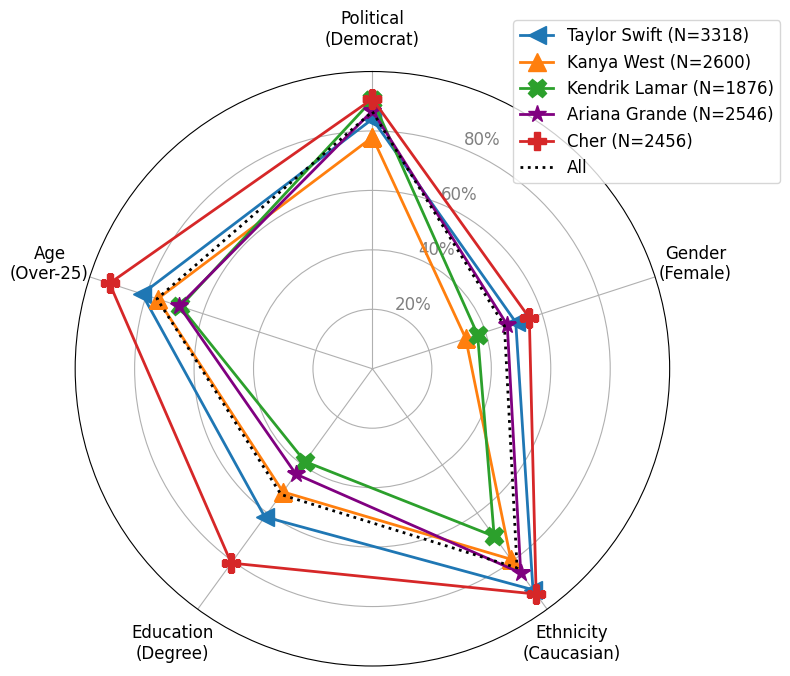

In [599]:
list_to_show = ['kendriklamar', 'cher', 'ArianaGrande', 'taylorswift13', 'kanyawest',]

accounts_to_show = all_topics[topic]['twitter_screen_name'].values
#accounts_to_show = all_topics['MusicalArtist'][all_topics['MusicalArtist']['twitter_screen_name'].isin(list_to_show)]['twitter_screen_name'].values

account_count_in_exploded[account_count_in_exploded['account_name'].isin(['taylorswift13','kanyewest','kendricklamar','cher','ArianaGrande'])][['account_name','tweet_id']]

import numpy as np
import matplotlib.pyplot as plt

# 1. Prepare the data from the image
metrics = {
        'political': 'Democrat',
        'gender': 'Female',
        'ethnicity': 'Caucasian', 
        'education': 'Degree',
        'age': 'Over-25',
    }

categories = [f"{k.capitalize()}\n({v})" for k, v in metrics.items()]
num_vars = len(categories)

data = {
    'taylorswift13': [0.840, 0.507, 0.919, 1-0.384, 0.815],
    'kanyewest':     [0.779, 0.330, 0.792, 1-0.488, 0.760],
    'kendricklama':  [0.905, 0.372, 0.697, 1-0.614, 0.679],
    'cher':          [0.908, 0.555, 0.937, 1-0.192, 0.930],
    'ArianaGrande': [0.868,	0.477,	0.849,	1-0.562,	0.684],
    'ALL':           [0.865, 0.467, 0.828, 1-0.477, 0.762]
}

# 2. Compute angle for each axis
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()

# The plot is a circle, so we need to "complete the loop" 
# by appending the start value to the end.
angles += angles[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

# 3. Helper function to draw each account
def add_to_radar(username, label, marker, color, linestyle='-'):
    values = data[username]
    values += values[:1]  # Repeat the first value to close the circular graph
    ax.plot(angles, values, marker, markersize=13, color=color, linewidth=2, label=label, linestyle=linestyle)
    ax.fill(angles, values, color=color, alpha=0.)

# 4. Add the artists
# < ^ X P
add_to_radar('taylorswift13', 'Taylor Swift (N=3318)', '<', '#1f77b4')
add_to_radar('kanyewest', 'Kanya West (N=2600)', '^', '#ff7f0e')
add_to_radar('kendricklama', 'Kendrik Lamar (N=1876)', 'X', '#2ca02c')
add_to_radar('ArianaGrande', 'Ariana Grande (N=2546)', '*', 'Purple')
add_to_radar('cher', 'Cher (N=2456)', 'P', '#d62728')

# 5. Add the "ALL" baseline with a distinct style (Loosely Dotted as discussed!)
add_to_radar('ALL', 'All', '', color='black', linestyle='dotted')

# 6. Final Styling
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)

# Draw axis lines and labels
ax.set_thetagrids(np.degrees(angles[:-1]), categories, size=12)
ax.tick_params(axis='x', pad=20)

# Go from 0 to 1 (since these look like percentages/proportions)
ax.set_ylim(0, 1)
ax.set_yticks([0.2, 0.4, 0.6, 0.8])
ax.set_yticklabels(["20%", "40%", "60%", "80%"], color="grey", size=12)

#plt.title("Account Demographics Comparison", size=20, y=1.1)
plt.legend(loc='upper right', bbox_to_anchor=(1.2, 1.1), fontsize=12)
plt.tight_layout()
plt.show()

In [511]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cycler



def get_name_from_screen_name(x):
    """
    Get the name of the account from the screen name.
    """
    if x in sv_cls.entities['screen_name'].values:
        return sv_cls.entities[sv_cls.entities['screen_name']==x]['name'].iloc[0]
    else:
        return None
    #sv_cls.entities[sv_cls.entities['screen_name']==x]['name'].iloc[0]

In [615]:

def create_manual_radar_plot():
    
    # 2. Setup Radar Chart Parameters
    metrics = {'political': 'Democrat', 'gender': 'Female', 'ethnicity': 'Caucasian', 
               'education': 'Degree', 'age': 'Over-25'}
    categories = [f"{k.capitalize()}\n({v})" for k, v in metrics.items()]
    num_vars = len(categories)
    angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
    angles += angles[:1]
    
    # Define marker list for rotation
    markers = ['<', '^', 'X', '*', 'P', 'o', 's']
    colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
    
    fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
    
    # 3. Dynamic Loop using enumerate for index-based styling
    for i, (account_name, values) in enumerate(data.items()):
        # Prepare data loop
        plot_values = values + values[:1]
        
        # Dynamic Style assignment based on "location" (index)
        label = get_name_from_mapping(account_name)
        
        if account_name.upper() == 'ALL':
            # Special styling for baseline
            color = 'black'
            linestyle = 'dotted'
            marker = ''
            linewidth = 2.5
        else:
            # Assign color and marker based on index
            color = colors[i % len(colors)]
            marker = markers[i % len(markers)]
            linestyle = '-'
            linewidth = 2
    
        ax.plot(angles, plot_values, marker=marker,markersize=13, color=color, 
                linewidth=linewidth, label=label, linestyle=linestyle)
        ax.fill(angles, plot_values, color=color, alpha=0)
    
    # 4. Final Styling
    ax.set_theta_offset(np.pi / 2)
    ax.set_theta_direction(-1)
    ax.set_thetagrids(np.degrees(angles[:-1]), categories, size=12)
    ax.tick_params(axis='x', pad=20)
    ax.set_ylim(0, 1)
    ax.set_yticks([0.2, 0.4, 0.6, 0.8])
    ax.set_yticklabels(["20%", "40%", "60%", "80%"], color="grey", size=11)
    
    #plt.title((category_name) , size=20, y=1.1, loc='left')
    
    plt.title((f'{category_name}') , size=20, y=1.1, loc='left')
    plt.legend(loc='upper right', bbox_to_anchor=(1.2, 1.1), fontsize=12)
    plt.tight_layout()
    plt.savefig(f'radar_plots/{category_name}.png', bbox_inches='tight')
    #plt.show()
    print("File Saved")

In [610]:
# 1. Your Data (The single source of truth)
data = {
    'taylorswift13': [0.840, 0.507, 0.919, 1-0.384, 0.815],
    'kanyewest':     [0.779, 0.330, 0.792, 1-0.488, 0.760],
    'kendricklama':  [0.905, 0.372, 0.697, 1-0.614, 0.679],
    'cher':          [0.908, 0.555, 0.937, 1-0.192, 0.930],
    'ALL':           [0.865, 0.467, 0.828, 1-0.477, 0.762]
}
category_name = "Musical Artists"

def get_name_from_mapping(account_name):
    # This represents your external logic/lookup
    mapping = {'taylorswift13': 'Taylor Swift', 'kanyewest': 'Kanye West', 
               'kendricklama': 'Kendrick Lamar', 'cher': 'Cher', 
               'ArianaGrande': 'Ariana Grande', 'ALL': 'Category Average'}
    return mapping.get(account_name, account_name)

create_manual_radar_plot()

In [ ]:
data = {
    'Ford':	[0.633,	0.271,	0.923,	0.587,	0.92],
    'Rivian':	[0.803,	0.115,	0.955,	0.752,	0.949],
    'Jeep':	[0.658,	0.315,	0.908,	0.483,	0.86],
    'Ferrari':	[0.673,	0.126,	0.857,	0.497,	0.844],
    'ALL':	[0.697,	0.222,	0.876,	0.532,	0.892],
}

category_name = "Car Manufacturers"

def get_name_from_mapping(account_name):
    # This represents your external logic/lookup
    mapping = {'Ford': 'Ford', 'Rivian': 'Rivian', 
               'Jeep': 'Jeep', 'Ferrari': 'Ferrari', 
                'ALL': 'Category Average'}
    return mapping.get(account_name, account_name)

create_manual_radar_plot()

File Saved


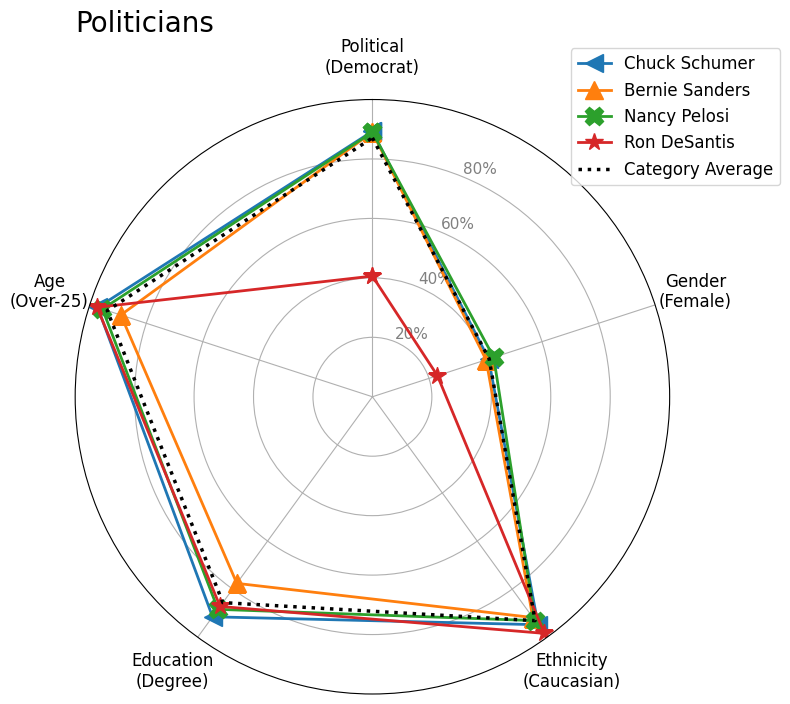

In [616]:
data = {
    'SenSchumer':	[0.893,	0.411,	0.948,	0.915,	0.972],
    'BernieSanders':	[0.89,	0.402,	0.918,	0.776,	0.89],
    'SpeakerPelosi':	[0.89,	0.429,	0.931,	0.884,	0.955],
    'GovRonDeSantis':	[0.406,	0.23,	0.984,	0.872,	0.974],
    'ALL':	[0.871,	0.413,	0.931,	0.856,	0.938],
    }

category_name = "Politicians"

def get_name_from_mapping(account_name):
    # This represents your external logic/lookup
    mapping = {'SenSchumer': 'Chuck Schumer', 'BernieSanders': 'Bernie Sanders', 
               'SpeakerPelosi': 'Nancy Pelosi', 'GovRonDeSantis': 'Ron DeSantis', 
                'ALL': 'Category Average'}
    return mapping.get(account_name, account_name)

create_manual_radar_plot()

File Saved


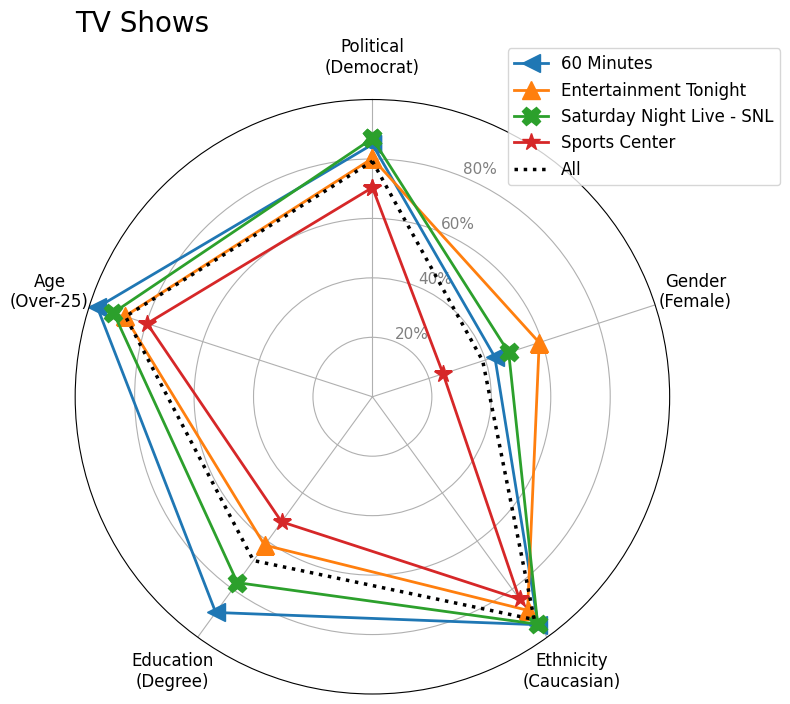

In [617]:
data = {
    '60Minutes':	[0.849,	0.433,	0.948,	0.897,	0.973],
    'etnow':	[0.802,	0.59,	0.888,	0.617,	0.876],
    'nbcsnl':	[0.869,	0.482,	0.946,	0.773,	0.916],
    'SportsCenter':	[0.704,	0.25,	0.842,	0.52,	0.797],
    'All':	[0.7924,	0.39025,	0.92645,	0.6811,	0.8733],
    }

category_name = "TV Shows"

def get_name_from_mapping(account_name):
    # This represents your external logic/lookup
    mapping = {'60Minutes': '60 Minutes', 'etnow': 'Entertainment Tonight', 
               'nbcsnl': 'Saturday Night Live - SNL', 'SportsCenter': 'Sports Center', 
                'ALL': 'Category Average'}
    return mapping.get(account_name, account_name)

create_manual_radar_plot()

File Saved


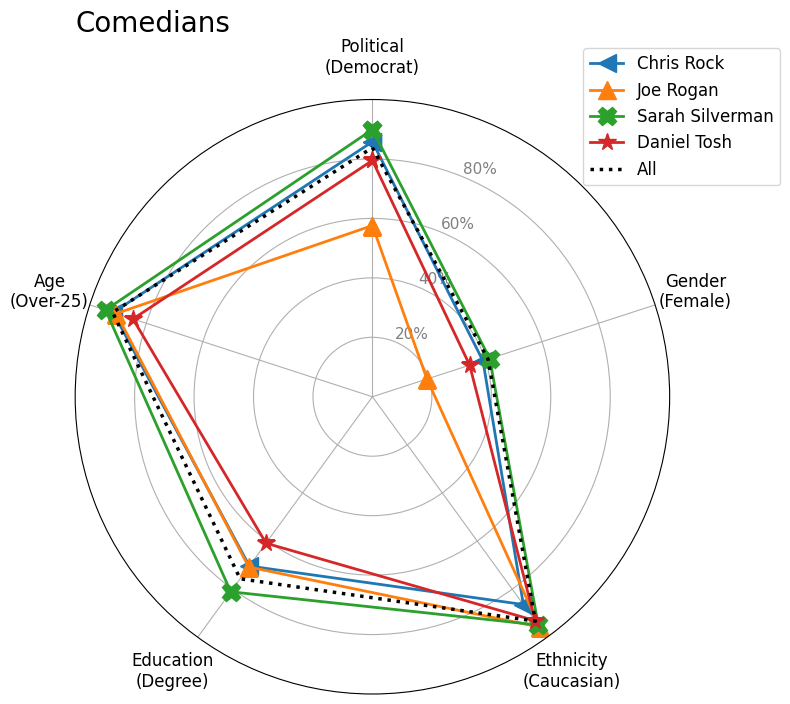

In [618]:
data = {
    'chrisrock':	[0.858,	0.391,	0.864,	0.704,	0.917],
    'joerogan':	[0.576,	0.193,	0.958,	0.708,	0.906],
    'SarahKSilverman':	[0.899,	0.415,	0.949,	0.811,	0.944],
    'danieltosh':	[0.795,	0.344,	0.931,	0.609,	0.847],
    'All':	[0.838,	0.409,	0.933,	0.757,	0.919],
    }

category_name = "Comedians"

def get_name_from_mapping(account_name):
    # This represents your external logic/lookup
    mapping = {'chrisrock': 'Chris Rock', 
               'joerogan': 'Joe Rogan', 
               'SarahKSilverman': 'Sarah Silverman',
               'danieltosh': 'Daniel Tosh', 
                'ALL': 'Category Average'}
    return mapping.get(account_name, account_name)

create_manual_radar_plot()

File Saved


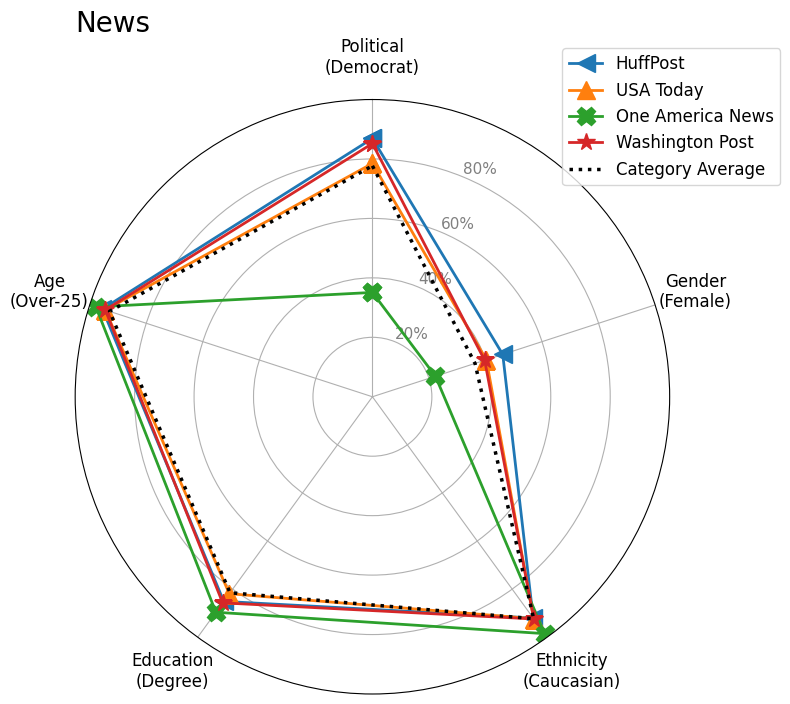

In [619]:
data = {
    'HuffPost':	[0.869,	0.461,	0.92,	0.851,	0.955],
    'USATODAY':	[0.785,	0.403,	0.923,	0.819,	0.945],
    'OANN':	[0.351,	0.223,	0.985,	0.896,	0.978],
    'washingtonpost':	[0.852,	0.397,	0.924,	0.857,	0.945],
    'ALL':	[0.777,	0.363,	0.923,	0.815,	0.93],
    }

category_name = "News"

def get_name_from_mapping(account_name):
    # This represents your external logic/lookup
    mapping = {'HuffPost': 'HuffPost', 
               'USATODAY': 'USA Today', 
               'OANN': 'One America News',
               'washingtonpost': 'Washington Post', 
                'ALL': 'Category Average'}
    return mapping.get(account_name, account_name)

create_manual_radar_plot()